# Bayesian estimation of the number of lost Latin texts: a Poisson-lognormal model

## The problem

Our data are a corpus of **citations**: late authors quote fragments of archaic works that are now lost. 
We observe **only** those works that were cited at least once by at least one of these sources: works that were never cited are structurally
invisible. 
This is a classic instance of **richness estimation in an unobserved population** (the "unseen species problem"), formally identical to the ecological problem of estimating the number of species from incomplete samples (Chao and jackknife estimators) or to multiple-list
capture–recapture.

Each **work** (author, title) plays the role of a "species", each **citing source** that of a
sampling site. The observed matrix
$$N_{ij} = \text{number of fragments of work } i \text{ cited by source } j$$
covers only the $S_{obs}$ works that were actually cited; the total number of works produced,
$S \ge S_{obs}$ (including those never cited, $S_0 = S - S_{obs}$), is the quantity one would like
to estimate — but we shall see that $S$ itself is **not identifiable** from the data, and that it
must be replaced by a better-posed estimand, $S(\tau)$.

## The model: Poisson-lognormal, with an exploratory cell-covariate extension

Each citation count is modelled as $N_{ij}\sim\text{Poisson}(\lambda_{ij})$. The **reference
model**, on which every reported estimate rests, is separable:
$$\lambda_{ij}=\exp\!\big(\xi_i+\eta_j\big),$$
where $\xi_i=\log X_i$ is the (log) "citability" of work $i$ and $\eta_j=\log Y_j$ the (log)
"transmission effort" of source $j$. The latent effects are given Gaussian distributions on the log
scale:
$$\xi_i \sim \mathcal N(\mu_x,\ s_x^2), \qquad \eta_j \sim \mathcal N(0,\ s_y^2).$$
An **exploratory extension** adds a vector $W_{ij}$ of **cell covariates** (specific to the
work × source pair), $\lambda_{ij}=\exp(\xi_i+\eta_j+W_{ij}^\top c)$. It is fitted in a dedicated
section, and it leaves the richness estimates unchanged. It uses

<!-- **Why *cell* covariates rather than row or column covariates?** The purely separable model
$\lambda_{ij}=\exp(\xi_i+\eta_j)$ is the log-linear independence model of a contingency table: its
sufficient statistics are *exactly* the margins (row totals and column totals). It has as many free
parameters ($60+167-1=226$) as the statistics it looks at, and therefore reproduces the margins
exactly at the maximum-likelihood estimate. **Consequently, a row covariate ($U_i$, acting on
$\xi_i$) or a column covariate ($V_j$, acting on $\eta_j$) cannot improve the fit** — there is
nothing left to fit on the margins; it acts only as a prior (shrinkage). This is a structural
property of the model, not an empirical finding. All genuinely discriminating information — the
effect of the *century*, the *affinity* between a type of source and a type of work — lives in the
$9\,794=(60{-}1)(167{-}1)$ degrees of freedom of the *interior* of the table, which the separable
model ignores. A cell covariate $W_{ij}$ is precisely what exploits that interior. 
The extension uses **two** of them (constructed below):
 -->

1. **Chronological distance** $W_{ij}=\log\!\big(1+\text{century}(j)-\text{century}(i)\big)$: a
   sixth-century CE grammarian is further away from a second-century BCE work than Cicero is. This
   is an **interaction** between work and source, invisible to row and column main effects.
2. **Source category × century of the work** $W_{ij}=\mathbb 1[\text{cat}(j)]\times
   (\text{century}(i)-\overline{\text{century}})$: source $j$ is a grammarian, a literary author or
   a commentator — do these three categories have chronological preferences of their own? This is
   an effect that distance alone (which depends only on the gap) cannot capture, and it combines a
   **reliable** source attribute (the type) with a reliable work attribute (the date). Since the
   three categories form a **complete** partition of the sources, they are encoded by a
   **sum-to-zero** contrast with two degrees of freedom rather than by three raw indicators (see the
   dedicated section): only the *differences* between categories are identifiable, not their common
   level.

## Inference: a fully continuous model, sampled by NUTS

The number of works never cited, $S_0$ (discrete), and their citabilities $\xi_0$
(trans-dimensional) **can be marginalised analytically**: the detected works form a *thinned*
Poisson process, whose likelihood involves neither discrete variables nor varying dimension (details
in the dedicated section). The model becomes a model with about 230 parameters, all continuous and
differentiable, sampled by **NUTS** (the No-U-Turn Sampler, adaptive HMC — through `numpyro`), with
the modern diagnostics: **$\hat R_\infty$** (the local $\hat R$ of Moins, Arbel, Dutfoy & Girard,
Bayesian Analysis 2025, in place of the rank-normalised $\hat R$ — see the diagnostics cell below),
ESS, divergences.

## Outline of the notebook

1. Loading the corpus, constructing the cell covariates, preliminary diagnostic.
2. The marginalised continuous model and its NUTS sampling; the **reference model** (without cell
   covariates).
3. **Non-identifiability of $S$** and its replacement by $S(\tau)$ (the number of works with at
   least probability $\tau$ of being detected) — a bounded and well-calibrated estimand.
4. Validation on simulated data (recovery, calibration, prior sensitivity).
5. **Cell covariates** (exploratory extension): chronological distance and source category — what
   does adding them change?
6. Diagnostics of the latent effects (citability and transmission effort under the reference model;
   threshold richness per century under the extension), posterior predictive checking, comparison with the classical estimators (Chao2,
   Chao–Bunge, the incidence jackknives, LCMCR) — each of them read on the $S(\tau)$ curve at
   the threshold it implicitly assumes — and with the Gamma-Poisson model.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("../src"))   # shared module lost_texts.py
os.makedirs("../figures", exist_ok=True)
from lost_texts import (setup_style, setup_numpyro, load_corpus, independence_deviance, fit_pln,
                        rhat_ess, rhat_inf_threshold, TAU_GRID, TAU_FINE, S_tau, print_S_tau_table, plot_S_tau_curve,
                        export_S_tau_curve, simulate_corpus, true_S_tau, check,
                        calibration_summary, print_calibration, pln_latent,
                        print_citability_summary, print_group_richness, plot_group_richness,
                        effort_shares, print_effort_table, plot_shrinkage, plot_cell_coefficients,
                        ppc, print_ppc_table, plot_ppc_hists, nonparam_estimators, print_nonparam,
                        load_lcmcr, implied_tau_table, plot_S_tau_estimators,
                        STATS, TYPES_EN)
setup_style()      # visual house style: ggplot theme and common font sizes (lost_texts.py, section 0)
setup_numpyro(4)

PATH = "../data/corpus_fragments_normalise.xlsx"   # paths are relative to notebooks/
COL_SCENARIO = 2   # 1, 2 or 3 -- handling of missing Author_fragment (anonymous sources)

# Everything the two notebooks have in common lives in `src/lost_texts.py`: the loader (with the
# century parser cent()), the sum-to-zero basis H3 and the two cell covariates, the estimand
# S(tau), the calibration protocol, the predictive statistics and the shared figures. The
# Gamma-Poisson notebook calls the SAME load_corpus(), so the two analyses bear on exactly the
# same matrix N by construction. To change the set of cell covariates, modify cell_design() there.
corpus = load_corpus(PATH, col_scenario=COL_SCENARIO)
Nv, rows, cols = corpus.N, corpus.rows, corpus.cols
Sobs, J = corpus.Sobs, corpus.J
wcf, scf, cat, wc_bar = corpus.wcf, corpus.scf, corpus.cat, corpus.wc_bar

corpus.describe(COL_SCENARIO)
corpus.describe_covariates()

/home/tmoins/Documents/witness_distribution/indirect_tradition/Latin_Archaic_Citations/frag_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[col_scenario=2] Matrix: 60 observed works x 167 sources | 2080 citations | singletons f1=23 | doubletons f2=8 | largest row=1122
Sources per category: grammarian=48, literary=77, commentator=42 (total 167)
Work centuries: -3.50 to -1.00, mean -1.95 (3 works with a missing century, imputed by the mean)
Chronological distance D: 0.00 to 2.97 | source-earlier-than-work pairs (D=0 imposed): 0/10020


**Observed corpus: 60 works × 167 sources, 2080 citations** (`col_scenario=2`: sources with no
identified author are distinguished by citing work rather than merged, see `load_corpus` — hence a
higher number of sources than a plain reading of `Author_fragment` would give), singletons $f_1=23$
(38 % of the works are cited only once), doubletons $f_2=8$, largest row $=1122$ (a single work
concentrates 54 % of all citations). This strong heterogeneity — many works barely visible, a
handful dominating — is the signature of a highly incomplete sample, and motivates everything that
follows.

**The cell covariates** are constructed here once and for all:

- **Chronological distance** `D` $=\log(1+\text{century}(j)-\text{century}(i))$. Every source in the
  corpus postdates every work, so the gap is always positive and the truncation at zero is never
  binding: the number of "source earlier than work" pairs is **0 out of 10,020**. No structural zero
  therefore needs to be imposed.
- **Source category × century of the work** `Tc`: each source is a grammarian, a literary author or
  a commentator (48, 77 and 42 sources respectively) — a **complete** partition, hence encoded not
  by three raw indicators but by a **sum-to-zero** contrast with two degrees of freedom (orthonormal
  basis `H3`, see `sum_to_zero_basis`): only the *differences* between categories are identifiable,
  not their common level (which would be absorbed by the row effect $\xi_i$).


**What we conclude from this cell.** The matrix is small, extremely sparse and dominated by one
work; the covariate design is well defined and the chronological ordering (all sources posterior to
all works) is clean. To change the set of cell covariates, it is enough to modify `cell_design`
in `src/lost_texts.py`, the module shared with the companion notebook.

# The marginalised continuous model, and its sampling by NUTS

The apparent obstacle to HMC/NUTS sampling is that the number of works never cited, $S_0$, is
*discrete* and that their citabilities $\xi_0$ are *trans-dimensional*. Both **marginalise
analytically**. Under $S\sim\text{Poisson}(\Lambda)$ with independent detection, the detected works
form a *thinned* Poisson process; the log-likelihood of the observed data can be written **without
any data augmentation** as

$$\log p=\underbrace{\sum_{i,j}\big[N_{ij}\,\theta_{ij}-e^{\theta_{ij}}\big]}_{\text{Poisson over the cells}}
\;+\;\sum_i\log\varphi(\xi_i;\mu_x,s_x)\;+\;\sum_j\log\varphi(\eta_j;0,s_y)\;+\;\log p_{\text{pop}},$$

with $\theta_{ij}=\xi_i+\eta_j+W_{ij}^\top c$. The population term encodes "how many works in total,
given that $S_{obs}$ of them were detected". The probability of non-detection depends on the century
of the work (hence on the sources that *could* have cited it, and on their category), so the
unobserved population is **stratified by century** $g$:

$$\pi_0(g)=\mathbb E_{\xi\sim\mathcal N(\mu_x,s_x^2)}\big[e^{-e^{\xi}\,Y_\bullet(g)}\big],
\qquad Y_\bullet(g)=\sum_j e^{\eta_j+W_{gj}^\top c},$$

where $\pi_0(g)$ is computed by **Gauss–Hermite quadrature** (smooth and differentiable) and
$Y_\bullet(g)$ is the transmission effort accessible to a work of century $g$ (distance and source
category included). Giving each century an intensity $\Lambda_g\sim\text{Gamma}(a_0/G,\,b_0)$ — the
prior mass being **divided among the $G$ strata**, so that the expected total production does not
depend on the number of strata — the observed count $n_g\sim\text{Poisson}(\Lambda_g(1-\pi_0(g)))$
marginalises (conjugate Gamma–Poisson) into a negative-binomial term
$$\log p_{\text{pop}}=\sum_g -\big(a_0/G+n_g\big)\log\!\big(b_0+1-\pi_0(g)\big).$$

> **The density of the observed $\xi_i$ remains the untilted $\varphi$** (the detection factor
> $e^{-\mu_i}$ is already carried by the zero cells of the Poisson sum): the population term
> therefore contains only $-(a_0/G+n_g)\log(b_0+1-\pi_0(g))$, and no additional factor. An earlier
> version added a spurious $+n_g\log(1-\pi_0)$, which crushed $s_x$, $\pi_0$ and the extrapolation.

**Implementation (`numpyro`).** **Non-centred** parametrisation $\xi_i=\mu_x+s_x z_i$,
$\eta_j=s_y\,\tilde v_j$, to avoid Neal's funnel; a **sum-to-zero constraint** on $\tilde v$
(orthonormal basis) to remove the identifiability ridge $(\xi+c,\eta-c)$ — the same construction is
reused to encode the three source categories (grammarian / literary / commentator) symmetrically
through $u_{\text{type}}$; $\Lambda_g$ and $S_0$ marginalised, giving **about 230 parameters, all
continuous**. $S(\tau)$ is reconstructed *a posteriori* (next section) from the draws, its unobserved
part using $\Lambda_g\mid\text{data}\sim\text{Gamma}(a_0/G+n_g,\ b_0+1-\pi_0(g))$.

*Where the code lives.* `fit_pln()`, the century strata (`build_strata`) and the a-posteriori reconstruction `S_tau()` are defined in **`src/lost_texts.py`**, the module shared with `Poisson_gamma.ipynb`, and imported in the first cell. `S_tau()` is the very same function in both notebooks — it dispatches on the family recorded in the `aux` descriptor returned by the fit — so the two analyses report the same estimand computed by the same code path.

In [3]:
# The model (fit_pln), the century strata (build_strata) and the a-posteriori reconstruction of
# S(tau) are defined in lost_texts.py. S_tau() is shared with the Gamma-Poisson notebook and
# dispatches on aux["family"], so that both notebooks report the same estimand computed by the
# same code path.
# --------------------------------------------------- REFERENCE MODEL (no cell covariate)
post, post_ch, ndiv, aux = fit_pln(Nv, wcf, scf, cat, wc_bar, cell=False, seed=0,
                                   warmup=2000, samples=2000, target_accept=0.97)
rmax, emin = rhat_ess(post_ch, ["mu_x", "s_x", "s_y"])
print(f"Reference (separable) model: divergences={ndiv} | max R-hat-infinity={rmax:.3f} "
      f"(threshold {rhat_inf_threshold(4):.3f}) | min ESS={emin:.0f}\n")
print(f"{'param':8s}{'median':>10s}{'95% CI':>22s}")
for k in ["mu_x", "s_x", "s_y"]:
    lo, md_, hi = np.quantile(post[k], [.025, .5, .975])
    print(f"{k:8s}{md_:10.3f}   [{lo:8.3f},{hi:9.3f}]")

Reference (separable) model: divergences=0 | max R-hat-infinity=1.024 (threshold 1.031) | min ESS=99

param       median                95% CI
mu_x       -10.915   [ -16.972,   -7.531]
s_x          3.607   [   2.341,    5.558]
s_y          1.365   [   1.210,    1.547]


**Reference model — results (real data, 4 NUTS chains).**

| parameter | median | 95% CI |
|---|---|---|
| $\mu_x$ | -10.92 | [-16.97, -7.53] |
| $s_x$ | 3.61 | [2.34, 5.56] |
| $s_y$ | 1.37 | [1.21, 1.55] |

Diagnostics: **no divergences, $\hat R_\infty\le1.024$ (5 % threshold 1.031), ESS $\ge99$**.

**Which $\hat R$?** The convergence diagnostic reported here is $\hat R_\infty$, the *local* $\hat R$
of Moins, Arbel, Dutfoy & Girard (*On the use of a local $\hat R$ to improve MCMC convergence
diagnostic*, Bayesian Analysis 20(1), 131–156, 2025 — reference implementation vendored in
`src/rhat_infinity.py`), and no longer the rank-normalised $\hat R$. 

Mixing is slower on $(\mu_x, s_x)$
than on $s_y$, as expected: raising $s_x$ and lowering $\mu_x$ both add mass to the low tail of
citability, so these two parameters move along a correlated ridge. **The width of the interval on
$s_x$ (2.3 to 5.6) is itself a signal**: the tail of the citability distribution — hence the mass of
works with very low detection probability — is only weakly constrained by the data.

**What we conclude from this cell.** The sampler works and the corpus supports a strongly
heterogeneous citability ($s_y\approx1.4$ against $s_x\approx3.6$: works differ from one another far
more than sources do). But the ESS of about 100 for 8000 draws, and the width of the interval on
$s_x$, are the first indication of the identifiability problem established formally in the next
section. These three parameters are sufficient to reconstruct everything that follows: threshold
richness $S(\tau)$, the latent effects, and the predictive checks.

# $S$ is not identifiable: why, and how to work around it

We observe 60 works (cited at least once) and want to estimate how
many *existed*, including those that left no trace at all. A work that left no trace is by definition
invisible: extrapolation has to proceed in the dark.

**Why $S$ is out of reach.** Give each work a probability of being cited at least once: widely
diffused works have one close to 1, obscure ones a minute value (0.0001 %). $S$ sums over *all*
works, including those with ridiculously small probability. Nothing in the data distinguishes "10
works at 0.0001 %" from "10 million": such works almost never leave a trace, so their number is
constrained by nothing observable. This is not a lack of power: **the information does not exist in
the data** — as we shall verify directly by calibration.

**The idea: stop counting the invisible.** We replace "how many works in total" by **"how many works
had at least a chance $\tau$ of being detected?"** — that is $S(\tau)$: fix a threshold $\tau$ (say
$\tau=0.5$) and count the works whose detection probability $1-e^{-\mu_i}$ (with
$\mu_i=\mathbb E[\text{citations of }i]$) exceeds $\tau$. Excluding the near-zero-probability region
removes exactly the region where the information was missing.

**A bound that holds without any model.** If a work has at least probability $\tau$ of being cited,
then on average at least a fraction $\tau$ of such works is actually observed. Since we observe
$S_{obs}$ works, there cannot be more than $S_{obs}/\tau$ of them above the threshold:
$$S(\tau)\ \le\ S_{obs}/\tau.$$
A hard bound, **true whatever the model** — unlike $S$, for which no finite bound exists.

**To keep in mind.** $\tau$ must be fixed *before* looking at the results. The smaller $\tau$, the
closer one gets to the non-identifiable problem (a gradual transition, see the curve below). And
$S(\tau)$ remains **relative to the surviving grammatical tradition**: it answers "how many works were
present enough to have had a chance of surviving in the sources we still have", not "how many
existed".

   tau   mu_tau  S(tau) median            95% CI  hard bound S_obs/tau
  0.75    1.386           37.0   [ 31.0,  43.0]                    80
  0.50    0.693           51.0   [ 43.0,  59.0]                   120
  0.30    0.357           67.0   [ 57.0,  79.0]                   200
  0.20    0.223           80.0   [ 67.0,  95.0]                   300
  0.10    0.105          103.0   [ 84.0, 128.0]                   600
  0.05    0.051          129.0   [ 99.0, 168.0]                  1200


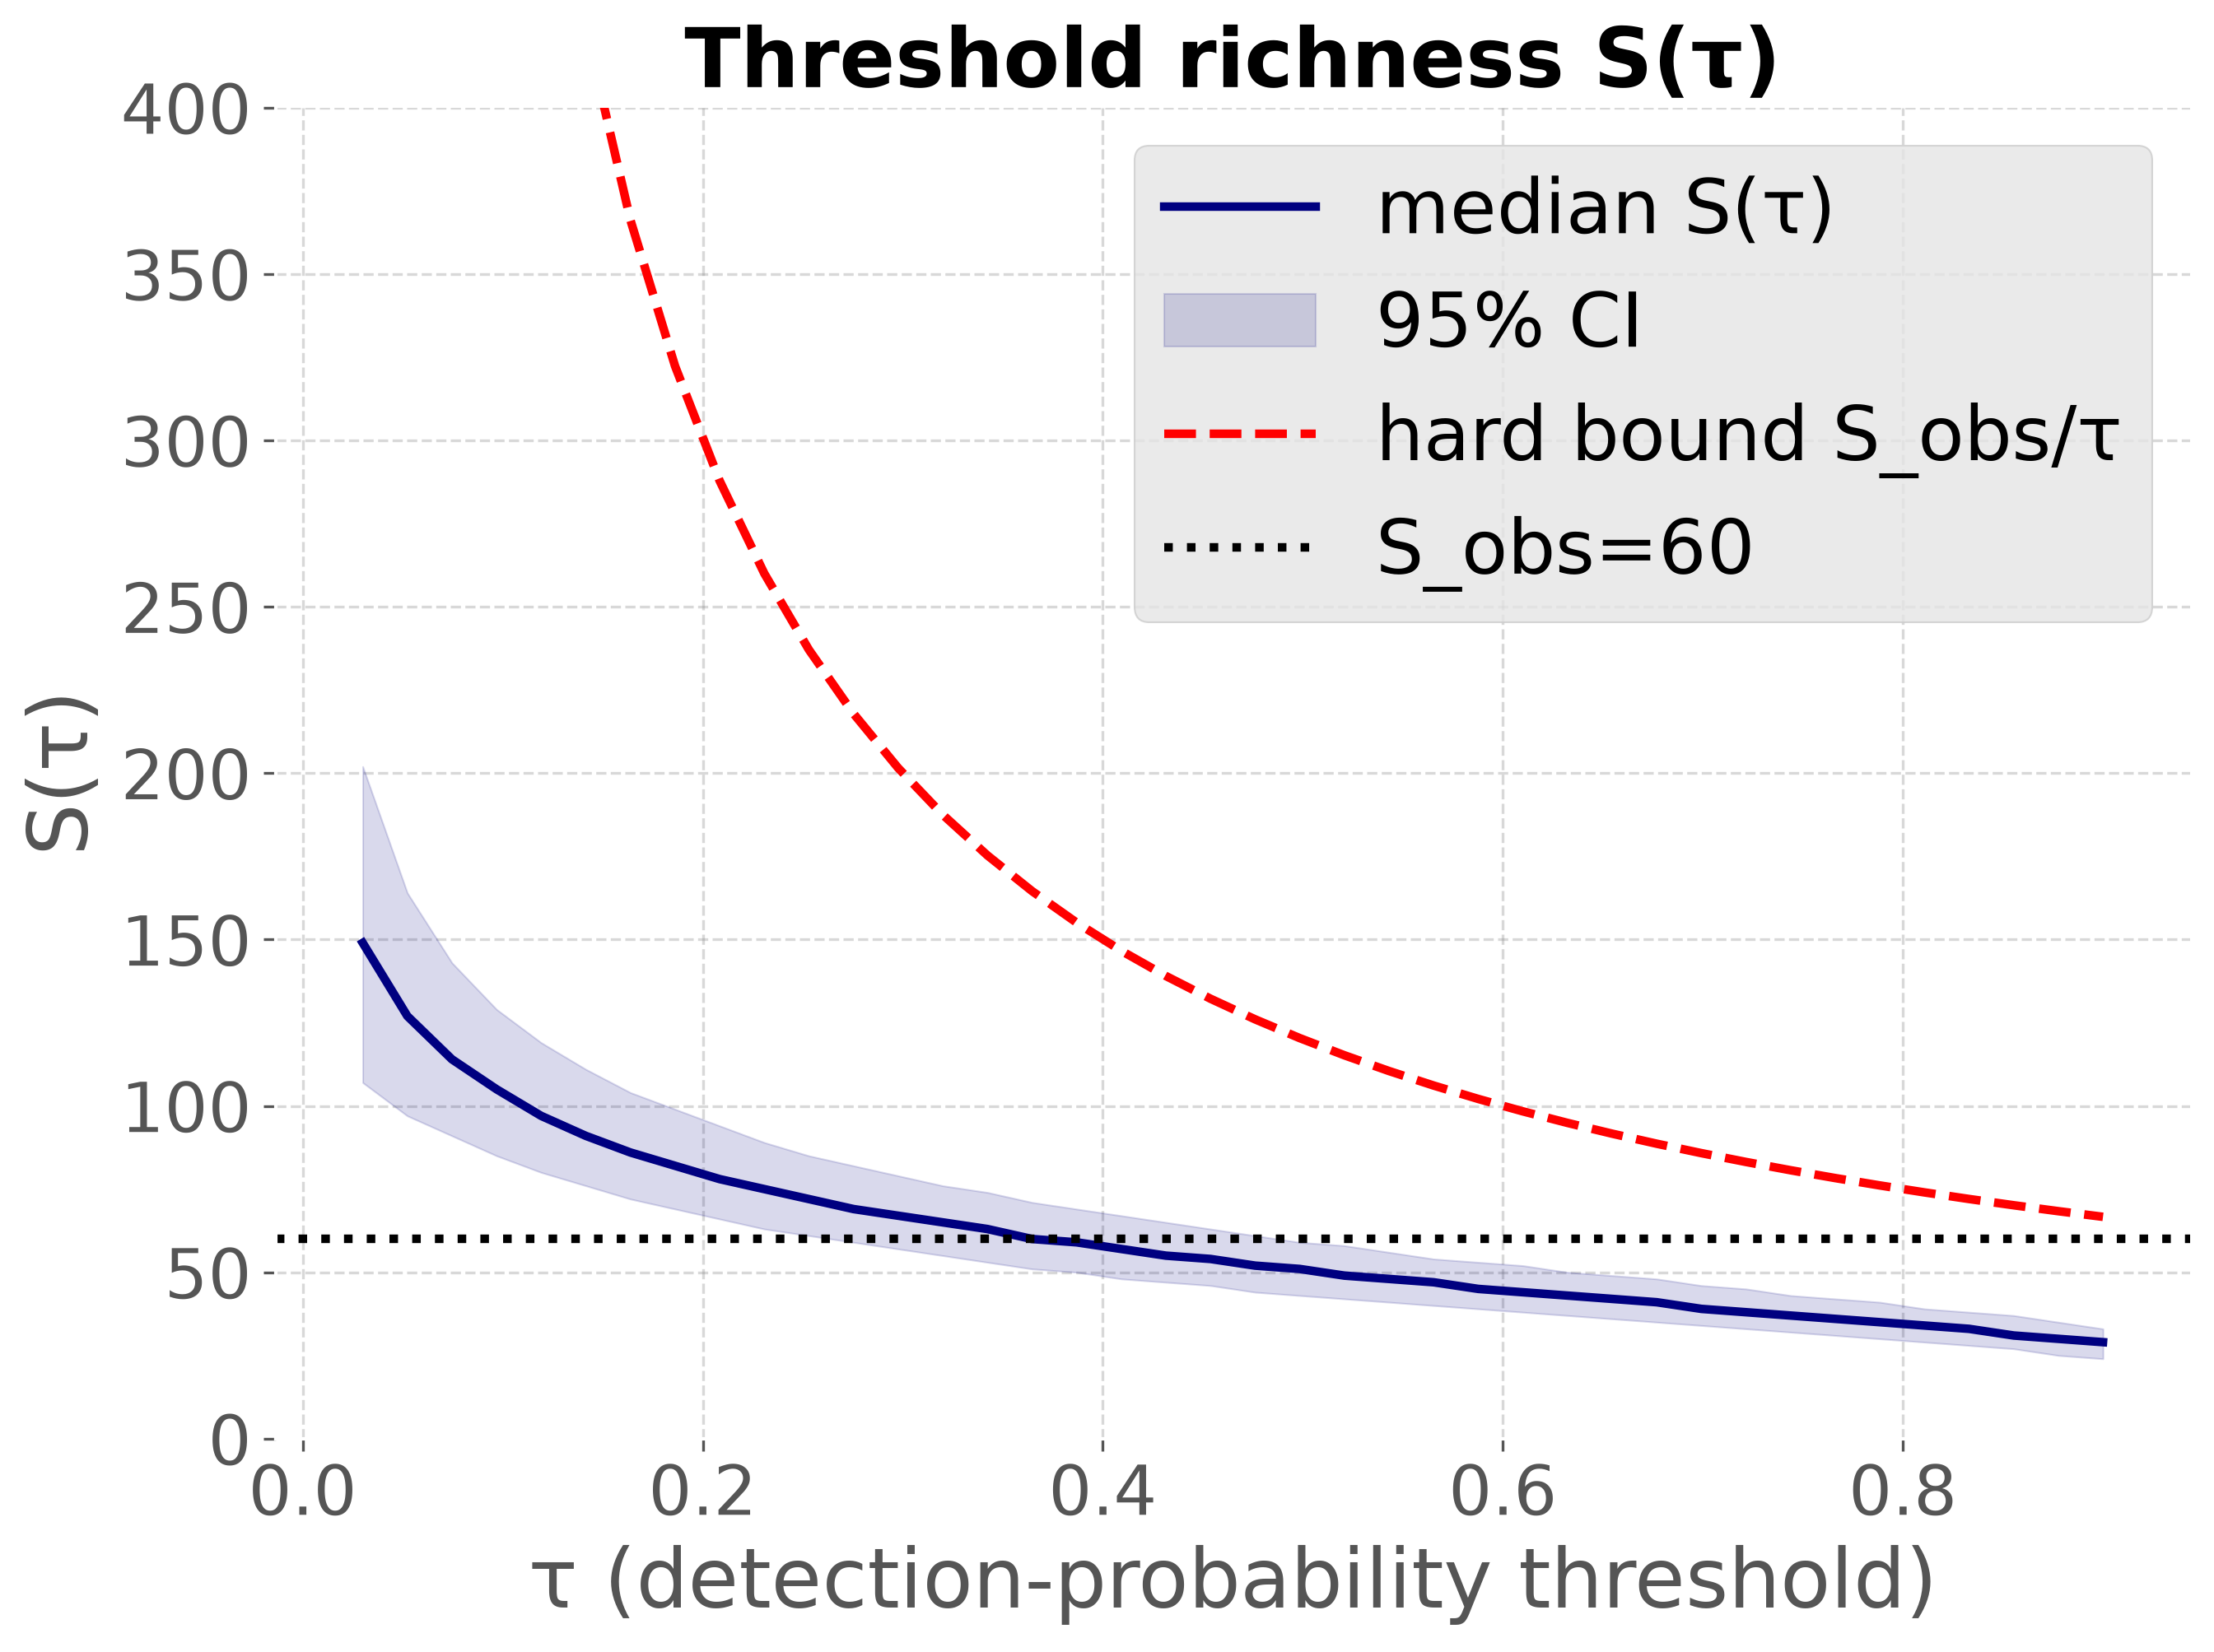

In [4]:
taus = [0.75, 0.5, 0.3, 0.2, 0.1, 0.05]
S_tau_ref, pdet_ref = S_tau(post, aux, taus, seed=1)
print_S_tau_table(S_tau_ref, taus, Sobs)

# TAU_GRID is the canonical grid shared with Poisson_gamma.ipynb (lost_texts.py), so that the
# curve exported here overlays exactly on the Gamma-Poisson one in the combined figure produced
# at the end of the companion notebook.
St = S_tau(post, aux, list(TAU_GRID), seed=2)[0]
plot_S_tau_curve(TAU_GRID, St, Sobs, ylim=400, title="Threshold richness S(τ)")
plt.show()

# Export for the cross-model S(tau) comparison figure at the end of Poisson_gamma.ipynb
export_S_tau_curve("../results/stau_lognormal.npz", TAU_GRID, St)

**Results (real data, reference model):**

| $\tau$ | $\mu_\tau$ | median $S(\tau)$ | 95% CI | hard bound $S_{obs}/\tau$ |
|---|---|---|---|---|
| 0.75 | 1.386 | 37 | [31, 43] | 80 |
| **0.50** | 0.693 | **51** | **[43, 59]** | 120 |
| 0.30 | 0.357 | 67 | [57, 79] | 200 |
| **0.20** | 0.223 | **80** | **[67, 95]** | 300 |
| 0.10 | 0.105 | 103 | [84, 128] | 600 |
| 0.05 | 0.051 | 129 | [99, 168] | 1200 |

**What the figure shows, and what we conclude from it.** The curve displays the announced
transition. For $\tau$ not too small (0.3 to 0.75) the posterior band is narrow and lies far below
the red hard bound $S_{obs}/\tau$: the data, not the bound and not the prior, are doing the work. As
$\tau$ decreases the median **takes off** (51 → 80 → 103 → 129 → …) with no plateau, and the band
widens: this is the visual signature of the non-identifiability of $S=\lim_{\tau\to0}S(\tau)$, since
every lowering of the threshold adds works of ever smaller citability that nothing in the data
counts. Concretely: **read the curve on the right-hand side, not on the left**; there is no value of
$S$ to be read off the left edge, and the absence of a plateau is the reason.

**The reading we retain: $S(0.5)\approx51$, 95% CI [43, 59], and $S(0.2)\approx80$, 95% CI [67, 95]**
— "about 51 archaic works had at least an even chance of being cited by the surviving grammatical
tradition; about 80 had at least a one-in-five chance". The two checks that follow show that these
two estimands are reliable whereas $S$ itself is not.

# Validation on simulated data

We check that the sampler recovers known parameters when the data really do come from the model
(recovery), and then that $S(\tau)$ is estimable where $S$ is not, in a realistic regime.
`simulate_corpus` implements the complete generative process — draw $S$, the centuries of the works,
the attributes of the sources, $\xi_i,\eta_j$, apply the cell covariates, draw $N_{ij}$, and finally
keep only the detected rows.

In [5]:
# ---- recovery: one detailed replicate, with a genuinely undetected population (pi0 ~ 0.25:
#      158 works produced, only 119 detected) -- the only regime in which the population term,
#      which drives the extrapolation, is actually exercised. simulate_corpus() implements the
#      complete generative process of BOTH notebooks, selected by its `family` argument. ----
sim = simulate_corpus("pln", J=64, Lam=180, mu_x=-3.5, s_x=1.4, s_y=1.3,
                      c_dist=-0.7, c_type=(-1.0, 0.3, 0.7), seed=3)
tr = sim["truth"]
ps, ps_ch, nd, ax_s = fit_pln(sim["N"], sim["wc"], sim["sc"], sim["cat"], sim["wc_bar"],
                              cell=True, seed=1)
St_s, _ = S_tau(ps, ax_s, [0.5, 0.2], seed=0)

print(f"truth: S={tr['S']}  S_obs={tr['Sobs']}  (divergences={nd})")
for nm in ["mu_x", "s_x", "s_y", "c_dist"]:
    check(nm, ps[nm], tr[nm])
c_type_true_ctr = tr["c_type"] - tr["c_type"].mean()   # identifiable (sum-to-zero) part of the truth
for k, t in enumerate(TYPES_EN):
    check(f"c_type[{t}]", ps["c_type"][:, k], c_type_true_ctr[k])
for t in [0.5, 0.2]:
    check(f"S({t})", St_s[t], true_S_tau(tr, t))

truth: S=158  S_obs=119  (divergences=0)
  mu_x                   truth   -3.500 | median   -4.063  95%CI[ -5.443,  -2.832]  OK
  s_x                    truth    1.400 | median    1.437  95%CI[  1.113,   1.942]  OK
  s_y                    truth    1.300 | median    1.472  95%CI[  1.178,   1.860]  OK
  c_dist                 truth   -0.700 | median   -0.382  95%CI[ -1.057,   0.316]  OK
  c_type[grammarian]     truth   -1.000 | median   -1.284  95%CI[ -1.602,  -0.985]  OK
  c_type[literary]       truth    0.300 | median    0.422  95%CI[  0.178,   0.672]  OK
  c_type[commentator]    truth    0.700 | median    0.861  95%CI[  0.571,   1.160]  OK
  S(0.5)                 truth  121.000 | median  122.000  95%CI[111.000, 134.000]  OK
  S(0.2)                 truth  147.000 | median  152.000  95%CI[136.000, 173.000]  OK


**Recovery (one detailed replicate).** A regime with a genuinely undetected population (158 works
produced, only 119 detected, $\pi_0\approx0.25$) and active cell covariates. No divergences.

| quantity | truth | posterior median | 95% CI | status |
|---|---|---|---|---|
| $\mu_x$ | -3.50 | -4.06 | [-5.44, -2.83] | OK |
| $s_x$ | 1.40 | 1.44 | [1.11, 1.94] | OK |
| $s_y$ | 1.30 | 1.47 | [1.18, 1.86] | OK |
| $c_{\text{dist}}$ | -0.70 | -0.38 | [-1.06, 0.32] | OK |
| $c_{\text{type}}$[grammarian] | -1.00 | -1.28 | [-1.60, -0.99] | OK |
| $c_{\text{type}}$[literary] | 0.30 | 0.42 | [0.18, 0.67] | OK |
| $c_{\text{type}}$[commentator] | 0.70 | 0.86 | [0.57, 1.16] | OK |
| $S(0.5)$ | 121 | 122 | [111, 134] | OK |
| $S(0.2)$ | 147 | 152 | [136, 173] | OK |

**What we conclude from this cell.** The implementation is correct in a regime in which the
population term is genuinely exercised ($\pi_0\approx0.25$, not $\approx0$): every quantity is
recovered inside its 95 % interval, including the **three category coefficients simultaneously** —
the sum-to-zero constraint ($c_{\text{type}}$ summing to zero by construction) does not prevent the
individual recovery of each. Note also which parameter is the weakest: $c_{\text{dist}}$ has the
widest interval and a median far from the truth (though containing it), because chronological
distance takes only a handful of values in a corpus of this size. That weakness is not an accident
of this replicate — it recurs on the real data, and should temper any substantive reading of
$c_{\text{dist}}$.

In [6]:
# Systematic calibration in the HEAVY-TAIL regime, matched to what the model actually infers on
# the corpus (mu_x ~ -10.9, s_x ~ 3.6, s_y ~ 1.37, J = 167 sources, and a Lambda chosen so that the
# simulated corpora have S_obs ~ 60, as observed). This is the relevant stress test: if S is poorly
# identified HERE, its intervals will be wide (so coverage comes "for free") and biased, whereas
# S(0.5) and S(0.2) should remain covered, tight AND nearly unbiased. calibration_summary()
# therefore also reports the CI width as a percentage of the truth: 100% coverage obtained through
# enormous intervals is not an estimate.
R = 12
records = {k: [] for k in ["S", "S05", "S02"]}
sobs_sim = []
for r in range(R):
    sim = simulate_corpus("pln", J=167, Lam=500, mu_x=-10.9, s_x=3.6, s_y=1.37, seed=500+r)
    tr = sim["truth"]; sobs_sim.append(tr["Sobs"])
    pr, _, _, axr = fit_pln(sim["N"], sim["wc"], sim["sc"], sim["cat"], sim["wc_bar"],
                            cell=False, seed=r, warmup=800, samples=800, chains=2)
    Str, _ = S_tau(pr, axr, [0.5, 0.2], seed=r)
    Sdraw = S_tau(pr, axr, [1e-3], seed=r)[0][1e-3]               # S = the tau -> 0 limit
    records["S"].append((Sdraw, tr["S"]))
    records["S05"].append((Str[0.5], true_S_tau(tr, 0.5)))
    records["S02"].append((Str[0.2], true_S_tau(tr, 0.2)))

print(f"R = {R} simulations, heavy-tail regime (mu_x=-10.9, s_x=3.6, s_y=1.37, Lam=500, J=167) | "
      f"median S_obs = {int(np.median(sobs_sim))}")
print_calibration(calibration_summary(records, error="bias"),
                  {"S": "S (tau->0)", "S05": "S(0.5)", "S02": "S(0.2)"})

R = 12 simulations, heavy-tail regime (mu_x=-10.9, s_x=3.6, s_y=1.37, Lam=500, J=167) | median S_obs = 69
estimand      95% CI cov.        median bias  95% CI width (% of truth)
S (tau->0)           83%             -33.7%                        86%
S(0.5)              100%              +0.9%                        31%
S(0.2)              100%              -0.7%                        33%


**Systematic calibration (12 simulations) in a heavy-tail regime matched to the corpus itself**
($\mu_x=-10.9$, $s_x=3.6$, $s_y=1.37$, $J=167$ sources, $\Lambda=500$ chosen so that the simulated
corpora contain about 60–70 detected works, as observed). For each estimand we report the coverage of
the 95 % intervals, the median bias, **and the median interval width as a percentage of the truth** —
because 100 % coverage obtained through an enormous interval is not an estimate.

| estimand | 95% CI coverage | median bias | 95% CI width (% of truth) |
|---|---|---|---|
| $S$ (limit $\tau\to0$) | **83 %** | **-34 %** | **86 %** |
| $S(0.5)$ | 100 % | +1 % | 31 % |
| $S(0.2)$ | 100 % | -1 % | 33 % |

**What we conclude from this cell.** The reading is unambiguous. **$S$ is not estimable in this
regime**: its coverage falls below nominal (83 % against 95 %) *despite* an interval whose width is
86 % of the quantity being estimated, and its median is biased downwards by a third. That is the
typical behaviour of a non-identified parameter — wide *and* wrong. **$S(0.5)$ and $S(0.2)$, by
contrast, are well calibrated**: nominal coverage, essentially no bias (+1 % / -1 %), and intervals
nearly three times tighter (31–33 % of the truth). The detectability threshold turns one
inestimable quantity into two estimable ones.

*Monte Carlo caveat.* With $R=12$ replicates the coverage rates themselves carry an uncertainty of
roughly ±10 points, so "83 %" and "100 %" should be read as "clearly below nominal" and "at or near
nominal", not as precise figures. The bias and width columns, which do not depend on a binary count,
are the more informative part of the table.

## The same diagnostic, directly on the data: sensitivity to the prior

The calibration study shows that $S$ is not estimable in the regime of this corpus. The same fact can
be seen a second time, without any simulation, by varying the prior on $s_x$ (the dispersion of
citability, which controls the tail): **if an estimand is identified by the data, it must not depend
on the prior.** We therefore expect $S(0.5)$ to be stable and $S(\tau\to0)$ to follow the prior.

In [7]:
print(f"{'prior on s_x':16s}{'s_x median':>12s}{'S(0.5)':>10s}{'S(0.2)':>10s}{'S(tau->0)':>14s}")
for scale, lbl in [(1.0, "HalfNormal(1)"), (3.0, "HalfNormal(3)"), (6.0, "HalfNormal(6)")]:
    p_, _, _, ax_ = fit_pln(Nv, wcf, scf, cat, wc_bar, cell=False, seed=0,
                            warmup=800, samples=800, chains=2, sx_prior=scale)
    St_ = S_tau(p_, ax_, [0.5, 0.2, 1e-3], seed=0)[0]
    print(f"{lbl:16s}{np.median(p_['s_x']):12.2f}{np.median(St_[0.5]):10.0f}{np.median(St_[0.2]):10.0f}"
          f"{np.median(St_[1e-3]):14.0f}")

prior on s_x      s_x median    S(0.5)    S(0.2)     S(tau->0)
HalfNormal(1)           2.61        53        81           167
HalfNormal(3)           3.47        51        80           254
HalfNormal(6)           3.54        51        80           262


**Results (real data).**

| prior on $s_x$ | median $s_x$ | $S(0.5)$ | $S(0.2)$ | $S(\tau\to0)$ |
|---|---|---|---|---|
| $\text{HalfNormal}(1)$ | 2.61 | 53 | 81 | 167 |
| $\text{HalfNormal}(3)$ | 3.47 | 51 | 80 | 254 |
| $\text{HalfNormal}(6)$ | 3.54 | 51 | 80 | 262 |

**What we conclude from this cell.** **$S(0.5)$ and $S(0.2)$ barely move** (51–53 and 80–81) when the
prior scale is multiplied by six, while $s_x$ goes from 2.6 to 3.5 and $S(\tau\to0)$ inflates from
167 to 262. The conclusion of the calibration study can therefore be read a second time, directly on
the data and without any simulation: $S(0.5)$ and $S(0.2)$ are determined by the data, $S$ follows
the prior. **From here on, $S(0.5)$ and $S(0.2)$ are the reference estimands;** $S$ is reported only
for the record, as a non-identified quantity.

# Cell covariates: chronological distance and source category

We explained in the introduction why, in this model, a *row* or *column* covariate can only act as a
prior: the separable model saturates the margins. The discriminating information lives in the
**interior** of the table, and is captured by **cell** covariates — which is what we assess here. We
compare the reference (separable) model with the model that adds:

- **chronological distance** $c_{\text{dist}}\cdot\log(1+\Delta\text{century})$ — an *interaction*
  between work and source, invisible to the main effects;
- **source category × century of the work** — do grammarians, literary authors and commentators
  over- or under-cite works of a given century relative to one another? This effect is distinct from
  distance, which depends only on the gap. The three categories form a **complete** partition of the
  sources (each source belongs to exactly one), so they are encoded by a **sum-to-zero** contrast with
  two degrees of freedom ($u_{\text{type}}$), from which we extract, a posteriori, one coefficient
  $c_{\text{type}}$ per category summing to zero — only the *differences* between categories are
  identifiable, not their common level (which would be absorbed by the row effect $\xi_i$).

The sign convention matters for the reading below: the covariate is multiplied by
$(\text{century}(i)-\overline{\text{century}})$, which is **larger for the more recent works**. A
**positive** $c_{\text{type}}$ therefore means that this category cites the *more recent* works
relatively more (equivalently: under-cites the oldest ones relative to the average of the three).

We look both at the effect on the coefficients (do these covariates carry information?) and at the
effect on richness $S(\tau)$ (do they change the count?).

Model with cell covariates: divergences=0 | max R-hat-infinity=1.022 (threshold 1.031) | min ESS=122

param            reference      with cells
mu_x                -10.91          -11.63
s_x                   3.61            3.74
s_y                   1.36            1.38
c_dist (chronological distance)   —      0.11  95%CI[-0.27,0.50]

c_type (source category × work century, sum-to-zero contrast -- only the differences between categories are identifiable):
  grammarian        0.47  95%CI[0.31,0.63]
  literary         -0.05  95%CI[-0.26,0.15]
  commentator      -0.42  95%CI[-0.63,-0.20]

S(0.5): reference median 51 95%CI[43,59]   with cells median 50 95%CI[43,59]
S(0.2): reference median 80 95%CI[67,95]   with cells median 79 95%CI[67,95]


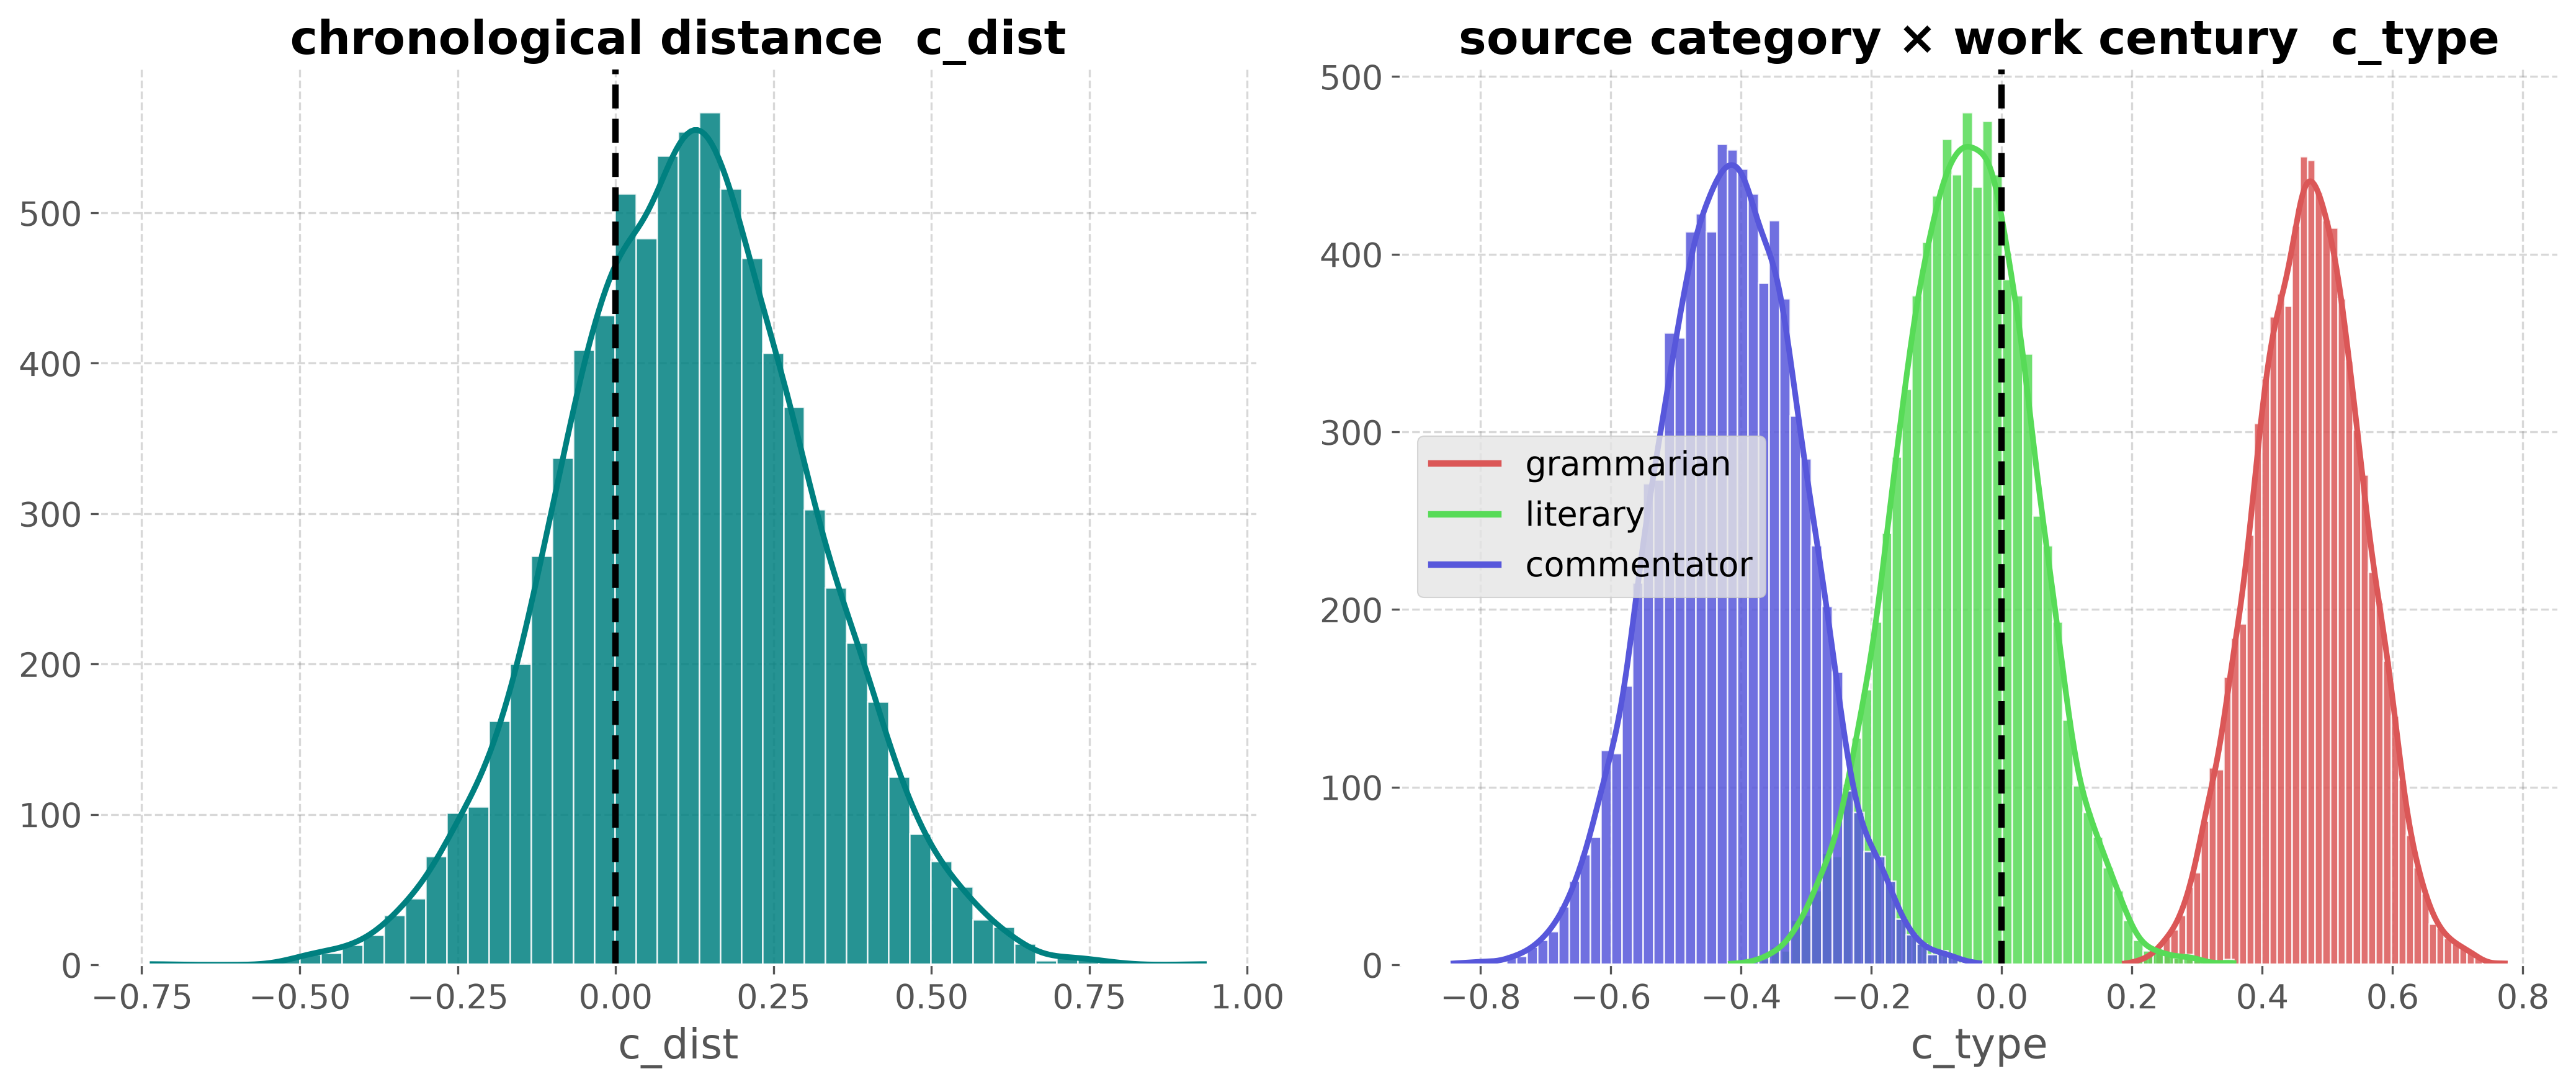

In [8]:
post_c, post_c_ch, ndiv_c, aux_c = fit_pln(Nv, wcf, scf, cat, wc_bar, cell=True, seed=0,
                                           warmup=2000, samples=2000, target_accept=0.97)
rmax_c, emin_c = rhat_ess(post_c_ch, ["mu_x", "s_x", "s_y", "c_dist", "u_type"])
print(f"Model with cell covariates: divergences={ndiv_c} | max R-hat-infinity={rmax_c:.3f} "
      f"(threshold {rhat_inf_threshold(4):.3f}) | min ESS={emin_c:.0f}\n")

print(f"{'param':12s}{'reference':>14s}{'with cells':>16s}")
for k in ["mu_x", "s_x", "s_y"]:
    print(f"{k:12s}{np.median(post[k]):14.2f}{np.median(post_c[k]):16.2f}")
lo, md_, hi = np.quantile(post_c["c_dist"], [.025, .5, .975])
print(f"{'c_dist (chronological distance)':12s}{'—':>4s}{md_:10.2f}  95%CI[{lo:.2f},{hi:.2f}]")
print("\nc_type (source category × work century, sum-to-zero contrast -- only the differences "
      "between categories are identifiable):")
for k, t in enumerate(TYPES_EN):
    lo, md_, hi = np.quantile(post_c["c_type"][:, k], [.025, .5, .975])
    print(f"  {t:14s}{md_:8.2f}  95%CI[{lo:.2f},{hi:.2f}]")

S_tau_c, pdet_c = S_tau(post_c, aux_c, [0.5, 0.2], seed=1)
print()
for t in [0.5, 0.2]:
    a_, b_ = S_tau_ref[t], S_tau_c[t]
    print(f"S({t}): reference median {np.median(a_):.0f} 95%CI[{np.quantile(a_,.025):.0f},{np.quantile(a_,.975):.0f}]"
          f"   with cells median {np.median(b_):.0f} 95%CI[{np.quantile(b_,.025):.0f},{np.quantile(b_,.975):.0f}]")

plot_cell_coefficients(post_c)
plt.show()

**Results (real data).** No divergences, $\hat R_\infty\le1.022$ (5 % threshold 1.031), min ESS $=122$.

| parameter | reference | with cell covariates |
|---|---|---|
| $\mu_x$ | -10.91 | -11.63 |
| $s_x$ | 3.61 | 3.74 |
| $s_y$ | 1.36 | 1.38 |
| $c_{\text{dist}}$ (distance) | — | 0.11, 95% CI [-0.27, 0.50] |
| $c_{\text{type}}$ (grammarian) | — | **0.47, 95% CI [0.31, 0.63]** |
| $c_{\text{type}}$ (literary) | — | -0.05, 95% CI [-0.26, 0.15] |
| $c_{\text{type}}$ (commentator) | — | **-0.42, 95% CI [-0.63, -0.20]** |
| $S(0.5)$ | 51 [43, 59] | 50 [43, 59] |
| $S(0.2)$ | 80 [67, 95] | 79 [67, 95] |

**What the two histograms show.** Left panel: the posterior of $c_{\text{dist}}$ is centred almost
exactly on zero and straddles it. Right panel: the three category posteriors are clearly separated,
grammarians on one side, commentators on the other, literary sources in between and overlapping zero.

**What we conclude from these figures.**

- **Chronological distance carries no detectable signal on this corpus** ($c_{\text{dist}}=0.11$,
  interval comfortably containing 0). This is a negative result, and it should be reported as one:
  once the source category is in the model, the sheer size of the gap between a work and the source
  citing it explains nothing further. The recovery study showed that this is also the coefficient the
  design identifies least well, so the correct statement is "no evidence of an effect", not "evidence
  of no effect".
- **The source category does carry a clear chronological signal, and it is an opposition between
  grammarians and commentators.** Recall the sign convention: the covariate multiplies
  $(\text{century}(i)-\overline{\text{century}})$, which is larger for the *more recent* works.
  Grammarians ($+0.47$, interval entirely positive) therefore cite the **later archaic works**
  (second to first century BCE — the world of Lucilius) relatively more, while commentators
  ($-0.42$, interval entirely negative) cite the **oldest** ones (Livius Andronicus, Naevius, Ennius)
  relatively more. Literary sources ($-0.05$) sit at the average of the three and show no effect.
  This is philologically readable: the commentary tradition on Virgil quarries archaic epic, whereas
  the lexicographical tradition quarries the satirists and the comic poets closest to it in time.
- **These effects do not move the richness estimate.** $S(0.5)$ and $S(0.2)$ are essentially
  identical with and without cell covariates (51 vs 50; 80 vs 79). The covariates enrich the
  *description* of the transmission mechanism (who cites what) without changing the *count* —
  consistent with their acting on the fine structure of the citations rather than on the overall
  volume captured. The reference model therefore remains the separable one: every estimate reported
  in the rest of this notebook (latent effects, predictive check, implied thresholds) is computed
  under it, and the covariate model is used only where the century is needed, for the per-century
  decomposition of the next section.

*A warning that must accompany this table.* These coefficients are **exploratory**. They were not
posited in advance, and they rest entirely on the chronological axis reconstructed by `cent()` from
the century labels of the spreadsheet — labels that are themselves editorial judgements, coarse
(one century, sometimes a range) and missing for three works. Their sign is therefore only as
reliable as that dating is; they describe a pattern worth investigating, not a tested hypothesis.

# Diagnostics of the latent effects

We now read off what the model says *about the works and the sources*: the citability of each work,
the Bayesian shrinkage of works that were barely seen, and the concentration of the transmission
effort — all under the **reference model**. We then ask, most usefully for a philologist, **how the
threshold richness of the archaic corpus is distributed across centuries**, together with the
fraction of it that the surviving tradition actually recorded. That last question needs the
**cell-covariate model**: in the reference model the century of a work has no channel through which
to act on $\lambda_{ij}$, so there is a single stratum and nothing to decompose.

Most 'citable' texts (mu = E[number of citations]):
  Lucilius | Satires                       N=1122 -> mu=1121  p_det=1.00
  Q. Ennius | Annales                      N= 592 -> mu=591  p_det=1.00
  Cn. Naevius | Bellum punicum             N=  82 -> mu=81  p_det=1.00
  Livius Andronicus | Odyssia              N=  39 -> mu=38  p_det=1.00

Singletons (N_i.=1, 23 texts): median mu=0.76, median detection probability=0.41
Most 'fragile' works (lowest p_det -- known to us, but they nearly disappeared):
  Cn.Naevius | Naevii epitaphium           N=   1  p_det=0.41
  Plaute | epigramma Plauti                N=   1  p_det=0.41
  Pompilius | Pompilii epigramma           N=   1  p_det=0.41
  Séius | Nidus                            N=   1  p_det=0.41

Threshold richness PER CENTURY S_g(tau) and threshold completeness obs_g(tau)/S_g(tau):

  century -> S_g(0.5) [95% CI]  |  obs_g/S_g(0.5) [95% CI]  (n_g works seen)
     -3.50 : S_g=  1.0 [0.0,2.0]   completeness=1.00 [0.00,1.00]   (n_g=1)
     -3.

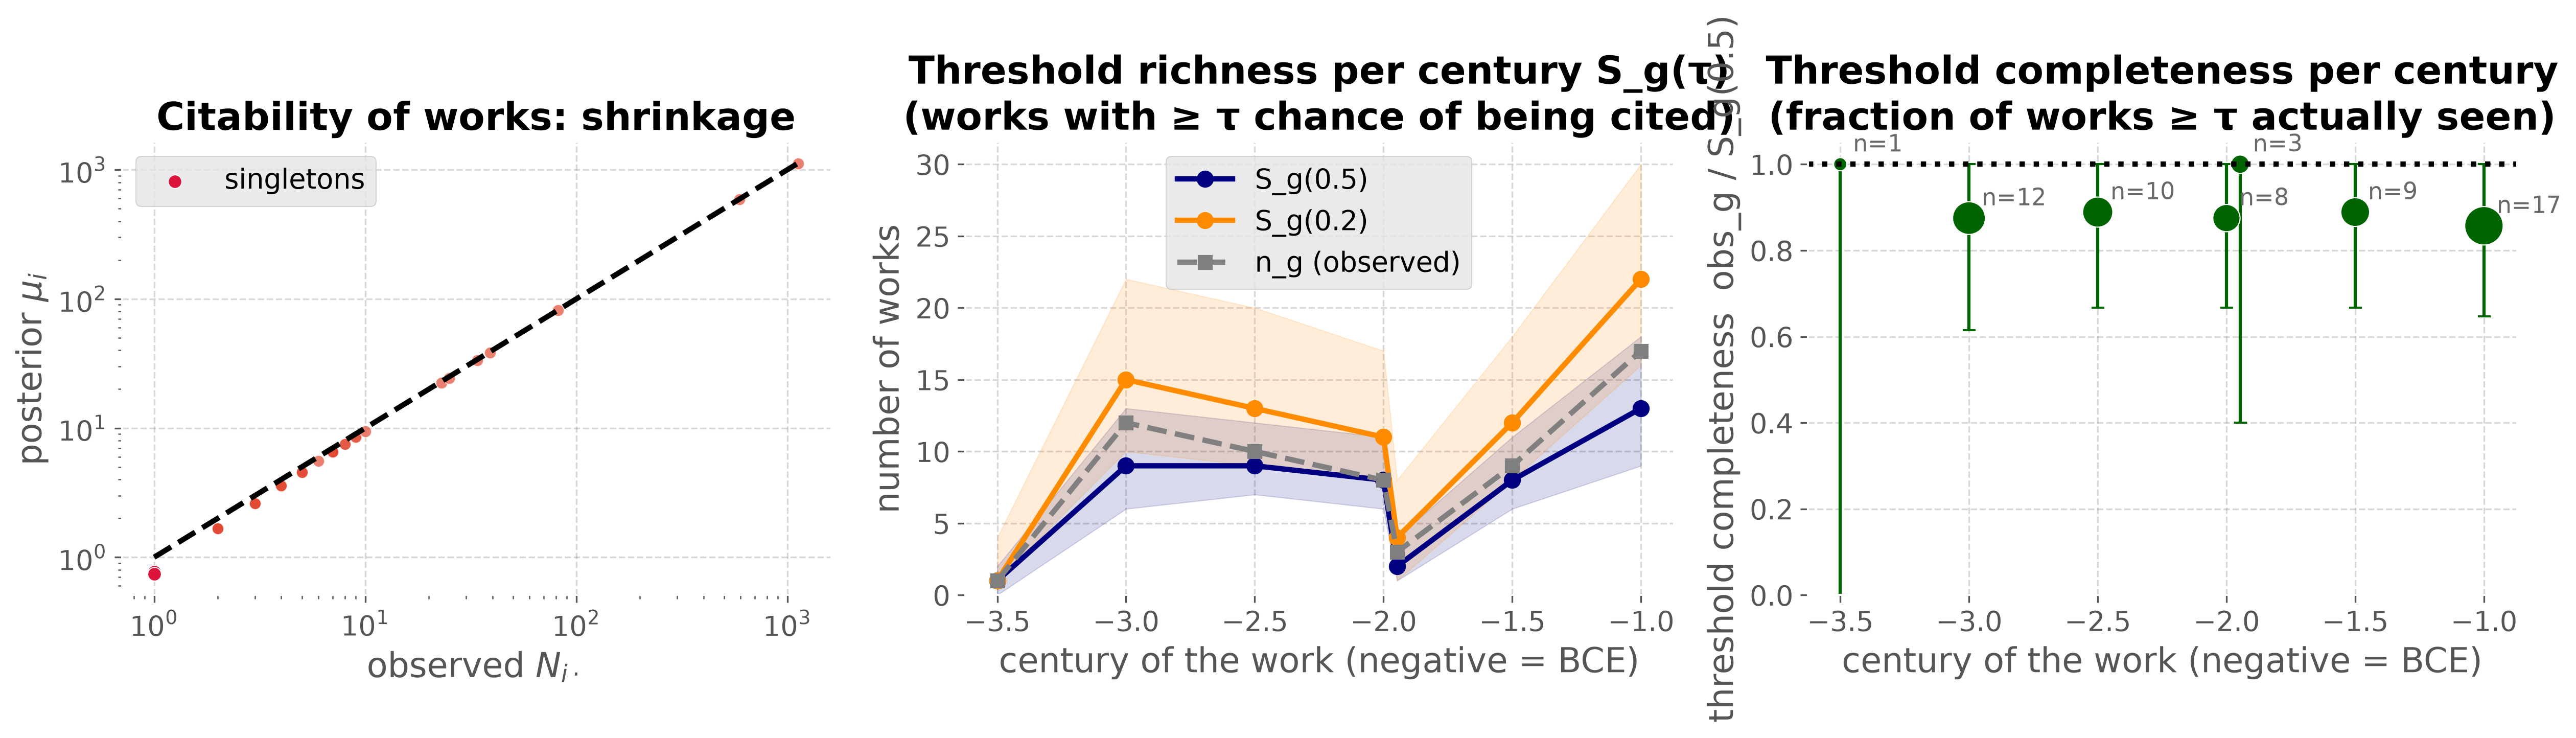

In [9]:
# Expected number of citations mu_i and detection probability 1-exp(-mu_i) of each work, under the
# REFERENCE (separable) model.
mu, pdet = pln_latent(post, aux)
Ni = Nv.sum(1)

# ---------- WORK SIDE: citability, shrinkage, fragile works (reference model) ----------
sing = print_citability_summary(rows, Ni, mu, pdet, top=4, fragile=True)

# ---------- WORK SIDE: threshold richness PER CENTURY S_g(tau), and threshold completeness ----------
# Needs the century strata, hence the CELL-COVARIATE model (the reference model has one stratum).
# See print_group_richness() for why 1-pi0(g) is replaced by S_g(tau) and obs_g(tau)/S_g(tau).
wc_g, n_per_g = aux_c["wc_g"], aux_c["n_g"]
_, _, Sg_c, obsg_c = S_tau(post_c, aux_c, [0.5, 0.2], seed=2, by_group=True)
Sq, Fq = print_group_richness(wc_g, n_per_g, Sg_c, obsg_c, [0.5, 0.2])

# ---------- SOURCE SIDE (briefly): concentration of the transmission effort (reference model) ----------
print()
w = effort_shares(post["eta"], log=True)
print_effort_table(cols, w, detail=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
plot_shrinkage(ax[0], Ni, mu.mean(0), sing, title="Citability of works: shrinkage")
plot_group_richness(ax[1], ax[2], wc_g, n_per_g, Sq, Fq, [0.5, 0.2], tau_ratio=0.5)
plt.tight_layout(); plt.show()

**Work side (reference model).**

- **Most citable works**: Lucilius (*Satires*, $N=1122$), Ennius (*Annales*, $N=592$), Naevius
  (*Bellum punicum*, $N=82$), Livius Andronicus (*Odyssia*, $N=39$) — detection probability $\approx1$:
  these works were never at risk of escaping us.
- **Singletons**: 23 texts with $N_{i\cdot}=1$, median $\mu\approx0.76$ and **median detection
  probability $\approx0.41$**. All singletons are shrunk to nearly the same value, so the four
  "most fragile" works listed (Naevius' epitaph, an epigram of Plautus, an epigram of Pompilius,
  Seius' *Nidus*) are in fact tied with every other singleton at $p_{\text{det}}\approx0.41$: known
  to us today, but with nearly a three-in-five chance of having vanished without a trace. It is this
  mass of barely detectable works that makes $S$ non-identifiable.

**Figure, left panel — shrinkage.** For well-attested works the posterior $\mu_i$ follows the
diagonal $\mu_i=N_{i\cdot}$: the model merely confirms the observed counts. For the singletons (in
red) it pulls the estimate below 1. **What we conclude: the model adds nothing where the data are
abundant, and does its work exactly where the evidence is thinnest** — which is the desired behaviour,
and also the reason the singletons, not Lucilius, drive the extrapolation.

**Figure, centre and right panels — chronological distribution of threshold richness (cell-covariate
model, the only one in which the century acts on detection).** The natural
quantity to plot here would be the raw "captured fraction" $1-\pi_0(g)$, but it is **not identified**
(the same argument as for $S$ — it depends on the unconstrained citability tail, and on this corpus
it comes out flat with uninterpretably wide intervals). Two **estimable** quantities are substituted
for it, both being the century-wise decomposition of the estimand already retained, $S(\tau)$:

- **$S_g(\tau)$** (centre panel): the number of works of century $g$ that had at least a chance $\tau$
  of being detected. It is $S(\tau)$ restricted to century $g$ (summing over $g$ returns $S(\tau)$),
  and it is calibrated exactly as $S(\tau)$ is — the calibration argument applies stratum by stratum.
- **threshold completeness $\text{obs}_g(\tau)/S_g(\tau)$** (right panel): among the works of century
  $g$ that were "citable enough to exceed $\tau$", the proportion the surviving tradition actually
  recorded. The numerator counts works **observed and above the threshold**, and not $n_g$: $n_g$
  also includes observed works below the threshold, which do not belong to the population
  $S_g(\tau)$ and would push the ratio above 1.

| century | $S_g(0.5)$ | completeness at 0.5 | $S_g(0.2)$ | completeness at 0.2 | $n_g$ observed |
|---|---|---|---|---|---|
| -3.5 | 1 [0, 2] | 1.00 | 1 [1, 4] | 1.00 | 1 |
| -3.0 | 9 [6, 13] | 0.88 [0.62, 1.00] | 15 [10, 22] | 0.65 [0.43, 0.91] | 12 |
| -2.5 | 9 [7, 12] | 0.89 [0.67, 1.00] | 13 [9, 20] | 0.67 [0.45, 0.91] | 10 |
| -2.0 | 8 [6, 11] | 0.88 [0.67, 1.00] | 11 [8, 17] | 0.70 [0.44, 1.00] | 8 |
| -1.95 (undated) | 2 [1, 4] | 1.00 | 4 [1, 8] | 0.67 | 3 |
| -1.5 | 8 [6, 11] | 0.89 [0.67, 1.00] | 12 [8, 18] | 0.69 [0.45, 1.00] | 9 |
| -1.0 | 13 [9, 18] | 0.86 [0.65, 1.00] | 22 [16, 30] | 0.67 [0.48, 0.88] | 17 |

**What we conclude from these two panels.** Three things, and no more.

1. **At $\tau=0.5$ the surviving tradition is close to complete: 86–89 % in every century**, with
   intervals reaching 1. In other words, of the archaic works that had an even chance of being cited,
   we are missing on the order of one in eight — a small and, importantly, *bounded* number.
2. **At $\tau=0.2$ completeness drops to about two thirds and stays there** (0.65–0.70). Lowering the
   threshold reveals works we do not have, exactly as expected; the drop is the interesting quantity,
   not the level.
3. **There is no chronological gradient.** The century-by-century intervals overlap almost entirely,
   at both thresholds. The apparent variation in $S_g$ tracks the observed counts $n_g$ (annotated on
   the right panel, and shown as the grey dashed line on the centre panel), not a difference in
   detectability: the channel through which the century acts on detection, $Y_\bullet(g)$, remains
   weak. **The honest conclusion is that this corpus does not resolve differences in survival between
   the third and the first century BCE.** The strata with very small counts — the single work at
   $-3.5$, and the three undated works imputed to the mean at $-1.95$ — should not be read at all;
   their $n_g$ is displayed precisely so that they can be discounted.

**Source side (brief, reference model).** Transmission is highly concentrated: Nonius Marcellus
(*Compendiosa doctrina*) alone carries about 36 % of the effort, the top three about 49 %, with a
Gini coefficient of 0.83. Note that this figure depends on the column convention (`col_scenario=2` splits an author
into one column per citing work); it is a description of the corpus as encoded, not an
edition-independent constant.

stat      observed  pred. med.  95% pred. interval  p Bayes
-- frequencies (citations per work) -----------------------
Sobs            60          62   [    41,     85]     0.94
f1              23          23   [    14,     36]     1.00
f2               8           8   [     3,     15]     1.00
tot           2080        1230   [   297,  35494]     0.63
maxc          1122         438   [    46,  24829]     0.62
-- incidences (distinct sources per work) -----------------
Q1              28          25   [    14,     38]     0.73
Q2               9           9   [     3,     16]     1.00
maxsrc         101          72   [    19,    167]     0.72


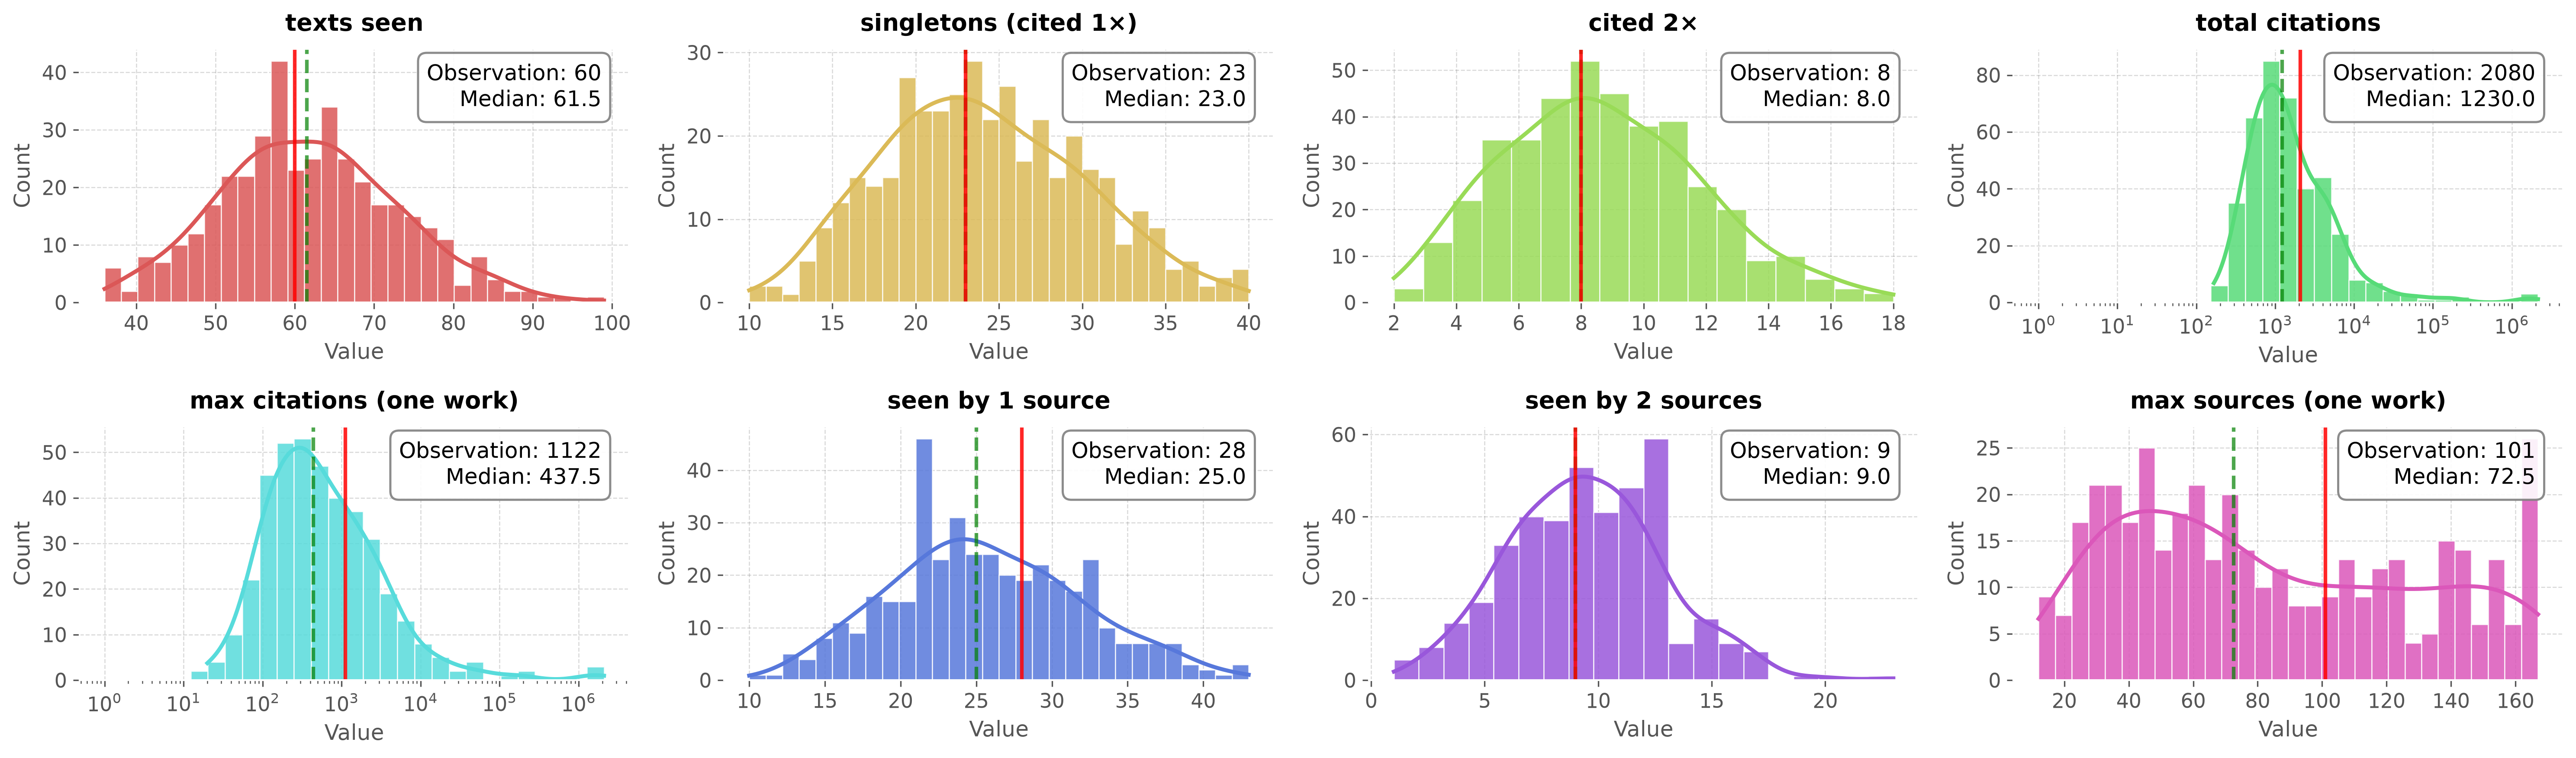

In [10]:
# Posterior predictive check of the REFERENCE model: Lambda|data ~ Gamma(a0+S_obs, b0+1-pi0),
# S ~ Poisson, citabilities xi ~ N(mu_x, s_x), citations N_ij ~ Poisson(exp(xi_i + eta_j)), then
# truncation -- and comparison with the observed corpus. ppc() is shared with the
# Gamma-Poisson notebook (it dispatches on aux["family"]) and always returns the SAME eight
# statistics: FREQUENCY statistics (how many works are seen once, twice, ...) and INCIDENCE
# statistics (how many distinct sources cite each work -- Q1, Q2, the structure that
# capture-recapture estimators exploit), so that the two notebooks are directly comparable.
obs, reps = ppc(post, aux, Nv)
print_ppc_table(obs, reps)

plot_ppc_hists(obs, reps, STATS, log_keys=("tot", "maxc"), ncols=4, figsize = (5 * 4, 3 * 2))
plt.savefig("../figures/ppc_lognormal.png")      # Figure 2 of the paper
plt.show()

# Export of the predictive draws for the cross-tabulation in Poisson_gamma.ipynb
np.savez("../results/ppc_lognormal.npz", **{k: np.asarray(v) for k, v in reps.items()})

**Posterior predictive check (reference model, 400 posterior draws).** For each draw we re-simulate
a complete corpus under the model ($\Lambda\mid$data, then $S$, citabilities, citations,
truncation) and compare **two families of statistics**: the *frequencies* (number of citations per
work) and the *incidences* (number of distinct sources per work — the structure that
capture-recapture estimators exploit).

| statistic | observed | predictive median | 95% predictive interval | $p$ Bayes |
|---|---|---|---|---|
| texts seen ($S_{obs}$) | 60 | 62 | [41, 85] | 0.94 |
| singletons ($f_1$) | 23 | 23 | [14, 36] | 1.00 |
| cited twice ($f_2$) | 8 | 8 | [3, 15] | 1.00 |
| total citations | 2080 | 1230 | [297, 35494] | 0.63 |
| max citations (one work) | 1122 | 438 | [46, 24829] | 0.62 |
| **seen by 1 source ($Q_1$)** | 28 | 25 | [14, 38] | 0.73 |
| **seen by 2 sources ($Q_2$)** | 9 | 9 | [3, 16] | 1.00 |
| **max sources (one work)** | 101 | 72 | [19, 167] | 0.72 |

**What the eight histograms show, and what we conclude from them.** The observed value (red line)
falls inside the bulk of the predictive distribution in all eight panels, and no $p$-value approaches
0.05. Two distinct conclusions follow, and they must not be conflated.

1. **A genuine success on the rarity statistics.** $f_1$, $Q_1$ and $Q_2$ are reproduced almost
   exactly (23 against 23; 28 against 25; 9 against 9) with intervals of a sensible width. These are
   the statistics that carry the information Chao2 and the incidence jackknives use, and they are the
   ones that discriminate between models — the companion Gamma-Poisson notebook fails on precisely
   these. That the lognormal tail reproduces them is the main evidence in its favour.
2. **A weak test on the volume statistics.** The predictive intervals for the total number of
   citations and for the maximum ($[297,\,35494]$ and $[46,\,24829]$, on a log scale in the figure)
   span two orders of magnitude. A heavy-tailed citability ($s_x\approx3.6$) produces a Lucilius
   easily, but it also occasionally produces corpora far larger than anything Latin literature could
   have contained. Passing this test is therefore **not** evidence that the model volume is right: the
   test has almost no power here. It should be reported as "not contradicted", not as "validated".
   This does not affect $S(\tau)$, which is governed by the body of the distribution rather than by
   its tail — but it is a real limitation of the generative model as a description of the corpus.


# Comparison with the classical estimators — and the threshold each one implicitly assumes

Three questions are settled in this section.

**Which classical estimators actually apply to this design.** The corpus is a multiple-list
capture–recapture design: the $J=167$ citing sources are the capture occasions, and a work is
"captured" by source $j$ if $j$ cites it. The data that follow from that design are the
**incidence** frequency counts $Q_k$ = number of works cited by exactly $k$ distinct sources.
**Chao1**, the estimator most often used in this literature, is *abundance*-based: it treats the
2080 individual citations as independent draws from a multinomial over works. That assumption is
untenable here — once a grammarian has excerpted a work he quotes it dozens or hundreds of times
(Nonius quotes Lucilius 1122 times), so citations arrive in bursts, and $f_1,f_2$ count clustered
rather than independent events. Chao1 is therefore **not reported**; we use **Chao2** instead, the
same bound recast on the incidence counts, where the replicates genuinely are the sources.

**Chao–Bunge (2002).** The one abundance-based estimator worth keeping is Chao & Bunge's, because
it is derived under exactly the *gamma-mixed Poisson* law that the companion notebook fits: it is
not a generic competitor but the non-parametric counterpart of the Gamma–Poisson model. Its
estimating equation is $\hat N^{*} = \sum_{k\ge2}f_k/\hat\theta$ with duplicated fraction
$\hat\theta = 1 - f_1\sum k^2f_k/n^2$, and it comes with the cut-off diagnostic the paper
prescribes (their equation 7), which this corpus turns out to need badly.

**What a single number for $S$ is really claiming.** Every one of these estimators returns one
number for the *non-identifiable* $S$. But each such number is the model's answer to "how many
works had detection probability at least $\tau$?" for exactly one value of $\tau$. Inverting the
$S(\tau)$ curve at each estimate recovers that $\tau$, and turns an unfalsifiable claim about the
total into a statement a historian can argue with.

In [11]:
# Chao2 (incidence), the incidence jackknives, and Chao-Bunge on both spectra.
# The last argument prints the cut-off stability scan that Chao & Bunge (2002) ask for.
est, fr = nonparam_estimators(Nv, cutoff=10)
print_nonparam(est, fr, Nv)

S_obs=60  m=167 sources | abundance f1=23 f2=8 | incidence Q1=28 Q2=9

estimator               estimate              95% CI
Chao2                        103           [76, 174]
Chao2-bc                      98           [73, 173]
Jack1                         88                  --
Jack2                        107                  --
Chao-Bunge (ab.)             125           [74, 359]
Chao-Bunge (inc.)            159           [77, 634]

Chao-Bunge duplicated fraction theta, uncut (estimator 2 of the paper): abundance -7.62, incidence -3.01
  -- theta <= 0 means the estimator is undefined and the cut-off form (7) is needed.

 cut-off   N (abundance)   theta   N (incidence)   theta
       4              94    0.23             116    0.18
       6             105    0.24             128    0.21
       8             121    0.24             134    0.20
      10             125    0.25             159    0.17
      15             125    0.25           16457    0.00
      20             125

**Results (real data).** $f_1=23,\ f_2=8$ (abundance), $Q_1=28,\ Q_2=9$ (incidence).

| estimator | basis | value | 95% CI |
|---|---|---|---|
| **Chao2** | incidence | **103** | [76, 174] |
| Chao2 bias-corrected | incidence | 98 | [73, 173] |
| Jack1 | incidence | 88 | — |
| Jack2 | incidence | 107 | — |
| **Chao–Bunge**, cut-off 10 | abundance | **125** | [74, 359] |
| Chao–Bunge, cut-off 10 | incidence | 159 | [77, 634] |

Two things are worth reading off the diagnostic underneath the table.

**Chao–Bunge is undefined on this corpus without a cut-off.** The uncut duplicated fraction is
$\hat\theta=-7.6$ on the abundance spectrum and $-3.0$ on the incidence spectrum. Chao & Bunge
anticipate this case explicitly — "a negative value of $\hat\theta$ implies that the overlap
measure is not high enough to produce a reliable estimate" — and it happens here for a reason we
have met repeatedly: $\sum k^2 f_k$ is dominated by a handful of enormous counts (Lucilius again).
This is the same *Lucilius effect* that the sensitivity check in the companion notebook isolates,
showing up now as an outright failure of a classical estimator rather than as a shifted posterior.

**With the cut-off, only the abundance version is stable.** Restricting the estimating equation to
counts $\le$ cut-off (their equation 7), the abundance estimate plateaus at **125 for cut-offs 10
to 20** — the stability region the paper asks one to look for — before collapsing at 25. The
incidence version has no such plateau (116 → 128 → 134 → 159 → 16457): with only 167 sources and a
work seen by 101 of them, the incidence spectrum has too few duplicated classes to identify
$\theta$. So we retain **Chao–Bunge = 125** on the abundance spectrum, and record the incidence
version as *not usable* rather than as a second estimate.

**Why the jackknives are still here, and what they are worth.** They survive the objection that
removed Chao1 — they are *incidence* estimators, reading only $Q_1$, $Q_2$ and the number of
occasions $m$, which is the capture–recapture framing this design supports. But they have a defect
of their own that should be stated. Burnham & Overton's bias correction carries a factor
$\frac{m-1}{m}$ that assumes the $m$ occasions are **exchangeable**, i.e. comparably effective. At
$m=167$ that factor is 0.994, so the two estimators collapse to

$$\text{Jack1}\;\approx\;S_{obs}+Q_1=88,\qquad \text{Jack2}\;\approx\;S_{obs}+2Q_1-Q_2=107,$$

fixed linear combinations of $Q_1$ and $Q_2$ from which the design has entirely disappeared. Jack1
says, literally, that every work seen by exactly one source has exactly one invisible twin. And the
exchangeability it assumes is what this corpus violates most brutally: Nonius alone accounts for
36 % of the transmission effort, with a Gini of 0.83 across sources. So they are reported as the
standard reference of the field, not as a third credible estimate — and their degeneracy is itself
part of the argument, since even the discipline's most cautious estimator turns out to sit below
the threshold the calibration certifies.

**What we conclude from this cell.** The defensible non-parametric estimates for this design span
**88–125**, with Chao2 = 103 as the central one.

In [12]:
# LCMCR (Manrique-Vallier 2016), fitted by scripts/lcmcr_check.py / scripts/lcmcr_check.R under
# three definitions of a "capture list". Falls back on the published values if the file is absent.
lcm = load_lcmcr("../results/lcmcr_results.csv")
if lcm is None:
    print("lcmcr_results.csv absent - published values: sources 60 [60,61], "
          "authors 60 [60,63], centuries 66 [61,75]")
    lcmcr_best = (66.0, 61.0, 75.0)
else:
    summ = lcm.groupby("paradigm").agg(J=("J", "first"), Sobs=("Sobs", "first"),
                                       N_lo=("N_lo", "median"), N_med=("N_med", "median"),
                                       N_hi=("N_hi", "median"))
    print(summ.to_string())
    print("\n(median over the 6 fits per paradigm: truncation K in {4,6,8} x DP prior "
          "Gamma(a,a), a in {0.25,1}; the spread across those 6 fits is <= 1 work)")
    r = summ.loc["centuries"]
    lcmcr_best = (float(r.N_med), float(r.N_lo), float(r.N_hi))

             J  Sobs  N_lo  N_med  N_hi
paradigm                               
authors     73    60  60.0   60.0  63.0
centuries   13    60  61.0   66.0  75.0
sources    167    60  60.0   60.0  61.0

(median over the 6 fits per paradigm: truncation K in {4,6,8} x DP prior Gamma(a,a), a in {0.25,1}; the spread across those 6 fits is <= 1 work)


**LCMCR is degenerate on this design.** Latent-class capture–recapture (Manrique-Vallier 2016) is
the natural reference estimator for "how many texts existed" on a multiple-list design, on the good
argument that the dominant dependence between citing authors is *common-cause* (shared florilegia),
which latent classes absorb by construction. `scripts/lcmcr_check.py` fits it to our matrix under the three
plausible definitions of a capture list:

| lists | $J$ | $S_{obs}$ | LCMCR $N$ | 95% CI |
|---|---|---|---|---|
| citing sources (the notebooks' unit) | 167 | 60 | **60** | [60, 61] |
| citing authors | 73 | 60 | **60** | [60, 63] |
| transmission centuries | 13 | 60 | **66** | [61, 75] |

The result is insensitive to the truncation $K\in\{4,6,8\}$ and to the DP prior
$\text{Gamma}(a,a)$, $a\in\{0.25,1\}$: the six fits per paradigm differ by at most one work.

**Why it degenerates, and why that is not a bug.** LCMCR estimates the all-zero cell as
$\hat N\,\prod_j(1-\lambda_j)$ within each latent class. With $J=167$ lists that product is
numerically zero for any class that has appreciable capture probability anywhere, so the model can
only place unobserved mass in a class whose $\lambda_j$ are near zero on *all* 167 lists — and
nothing in the observed patterns calls such a class into being. The estimate is therefore pinned
at $S_{obs}$ by the arithmetic of a large product, not by evidence. Aggregating sources into 13
centuries relieves the arithmetic and buys exactly six extra works.

**What we conclude from this cell.** LCMCR is not a competing estimate of richness here; it is a
*measurement of how little the incidence patterns alone constrain the unobserved cell*. Its
answer, +0 to +10 % over $S_{obs}$, against Chao2's +72 % and this model's $S(0.2)=80$, is the
honest non-parametric floor: everything above it is bought with a parametric assumption about the
low tail. That is an argument for reporting $S(\tau)$, not $S$ — and a caution against treating
LCMCR as the reference tool for a corpus of this shape. It is the reference tool for a design with
few, broad, comparably-effective lists; this design is the opposite one.

estimator                   S estimate   implied tau       95% CI on tau
Chao2                              103         0.110      [0.057, 0.169]
Chao2-bc                            98         0.130      [0.074, 0.189]
Jack1                               88         0.170      [0.113, 0.241]
Jack2                              107         0.101      [0.049, 0.157]
Chao-Bunge (ab.)                   125         0.063      [0.020, 0.108]
Chao-Bunge (inc.)                  159         0.028      [0.005, 0.059]
LCMCR (centuries)                   66         0.323      [0.242, 0.415]
S_obs (no extrapolation)            60         0.386      [0.298, 0.490]


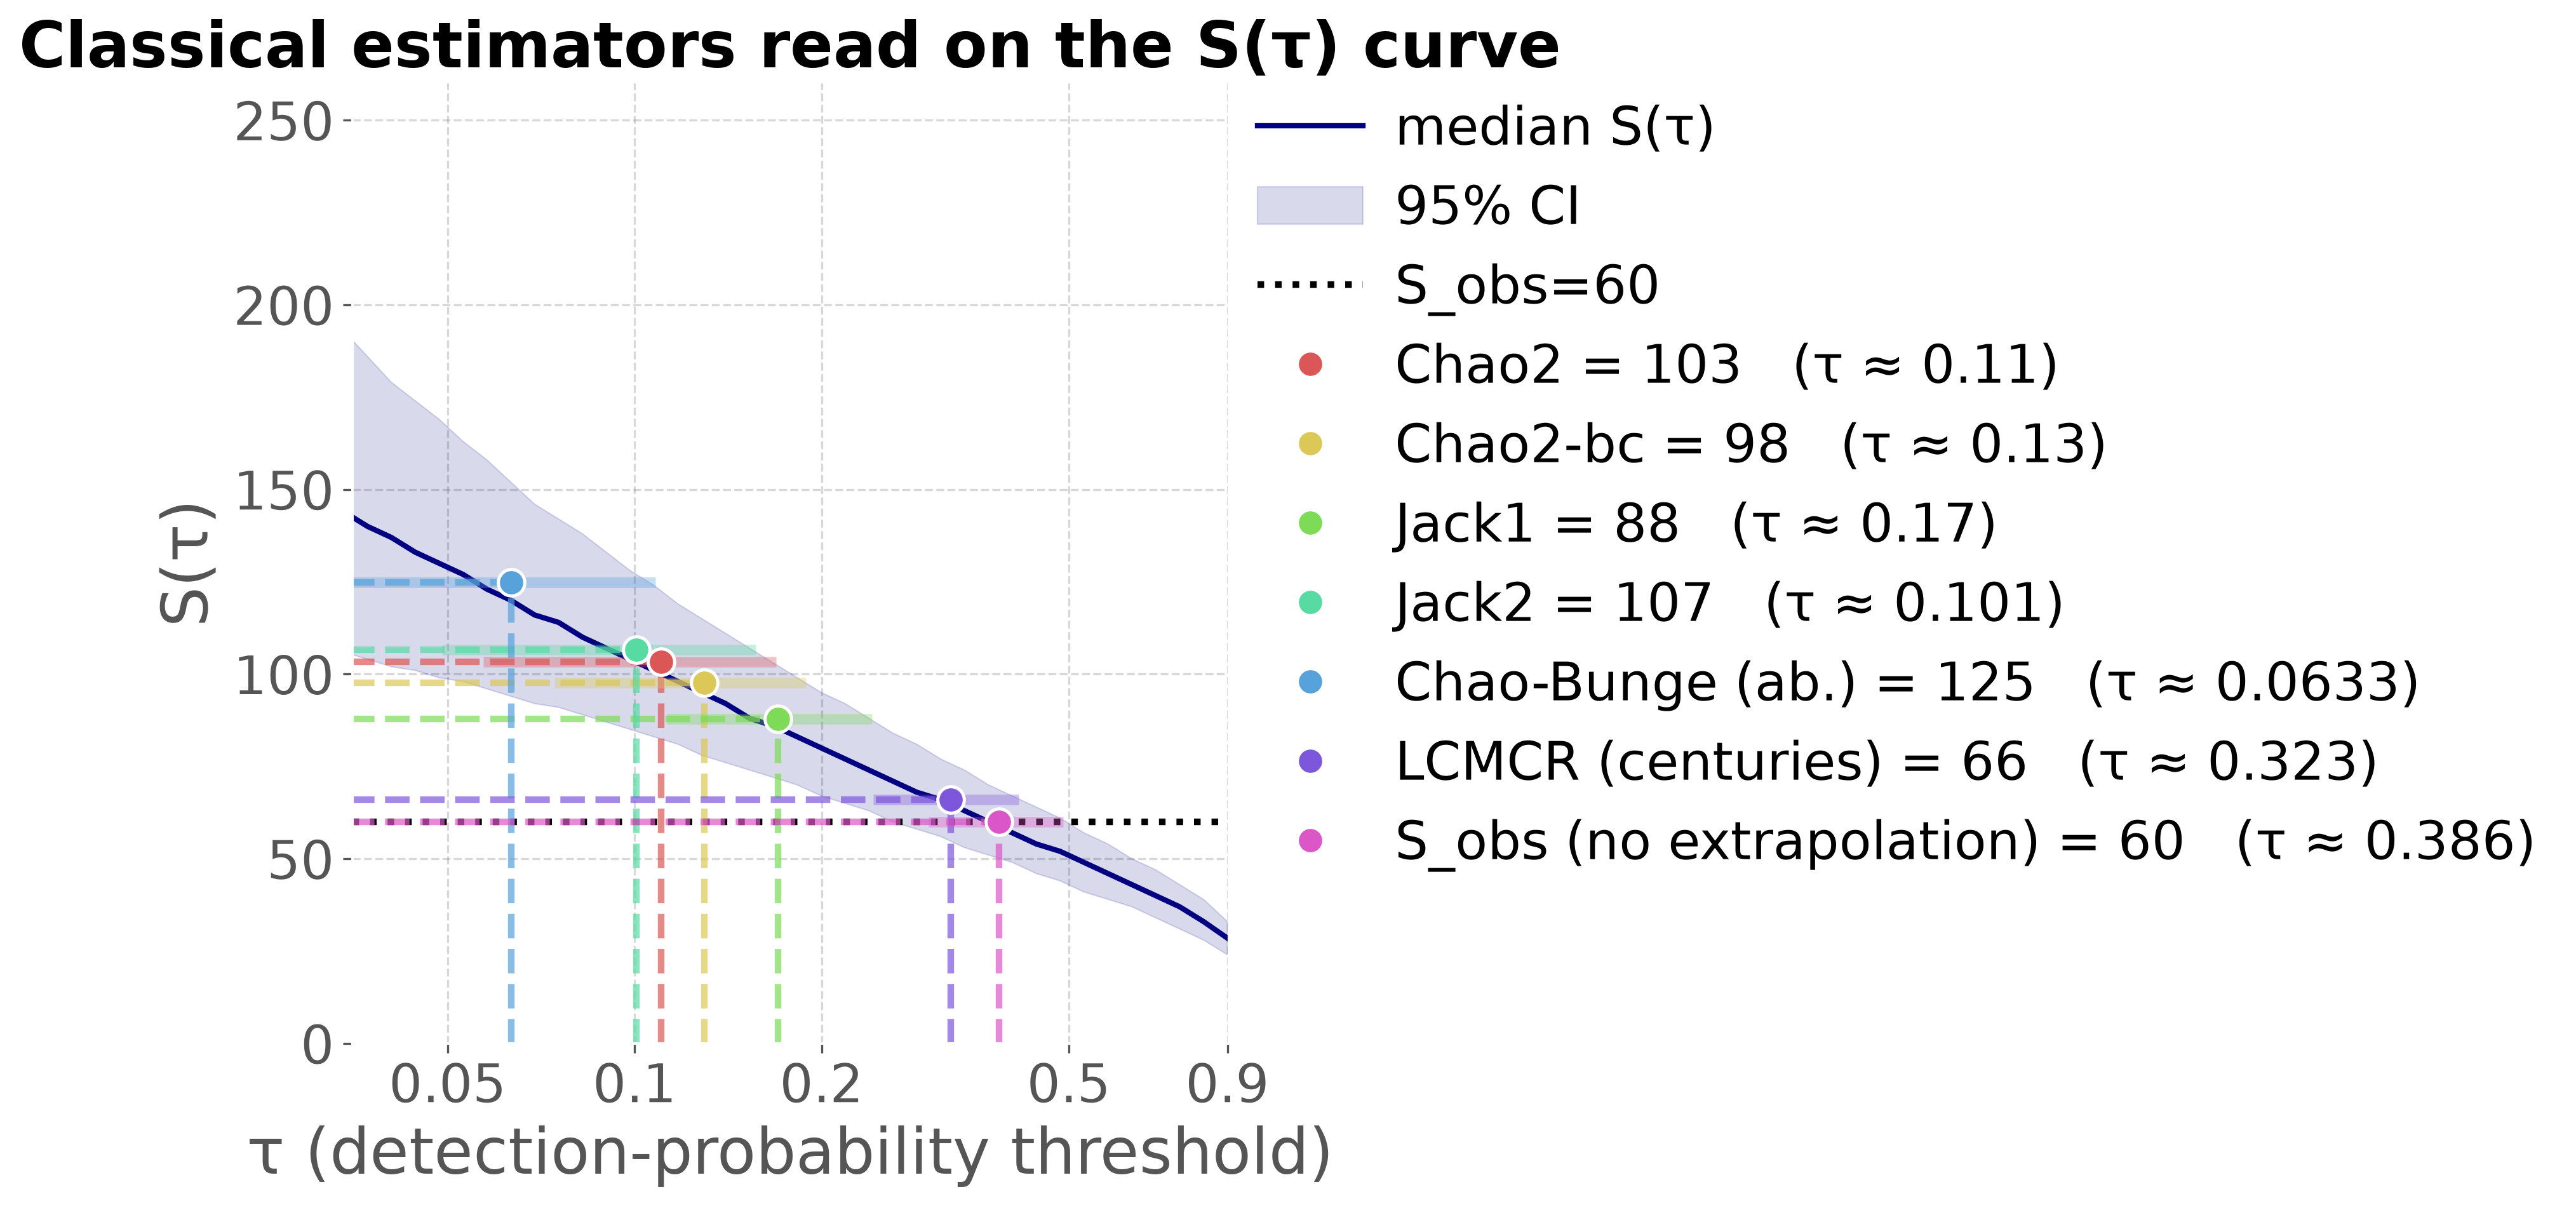

In [13]:
# Invert the S(tau) curve at each estimate: which detection threshold does each number
# implicitly assume? TAU_FINE is log-spaced down to 0.002 because some estimates land far below
# the tau=0.03 left edge of the display grid. Reference model.
St_fine = S_tau(post, aux, list(TAU_FINE), seed=3)[0]
est_rows = implied_tau_table(est, TAU_FINE, St_fine, Sobs=Sobs,
                             extra={"LCMCR (centuries)": lcmcr_best})

plot_S_tau_estimators(TAU_FINE, St_fine, Sobs,
                      [r for r in est_rows if r[0] != "Chao-Bunge (inc.)"], ylim=260)
plt.show()

**The threshold each estimator implicitly assumes** (reference model). Each $\tau$ is obtained by
inverting the curve *draw by draw*, so it carries its own 95 % interval.

| estimator | $S$ estimate | implied $\tau$ | 95% CI on $\tau$ | reading |
|---|---|---|---|---|
| $S_{obs}$ (no extrapolation) | 60 | 0.39 | [0.30, 0.49] | counts only works that were near-certain to be cited |
| LCMCR (centuries) | 66 | 0.32 | [0.24, 0.42] | one in three |
| Jack1 | 88 | 0.17 | [0.11, 0.24] | one in six |
| **Chao2** | **103** | **0.11** | [0.06, 0.17] | **one in nine** |
| Jack2 | 107 | 0.10 | [0.05, 0.16] | one in ten |
| Chao–Bunge (abundance) | 125 | 0.063 | [0.02, 0.11] | one in sixteen |

**How to read the figure.** Every classical estimator becomes a *point on our curve*. Its height is
the number of works it claims; its abscissa is the detection threshold that number silently
corresponds to. The ordering is no longer a disagreement about a quantity — it is a disagreement
about how faint a work is allowed to be and still be counted, and once stated that way it is a
question a Latinist can adjudicate.

**What we conclude from this cell.** Three things.

1. **The spread between the classical estimators is a spread in $\tau$, not in accuracy.** They run
   from $\tau=0.32$ (LCMCR) to $\tau=0.063$ (Chao–Bunge) — a factor of five in stringency. None of
   them says which threshold it is using, because none of them has the concept; that is precisely
   the information $S(\tau)$ adds.
2. **Chao2 is not a "lower bound on $S$" in any useful sense — it is an estimate of $S(0.11)$.**
   Calling it a bound on the total is what makes it look conservative; read at its own threshold it
   is a perfectly ordinary point on a curve whose left end we have argued at length is not
   identified. Our $S(0.2)=80$ [67, 95] and Chao2 = 103 [76, 174] are not rivals: they are two
   readings of the same curve at two thresholds, and the model's interval at a *fixed* threshold is
   half as wide as Chao2's.
3. **The classical estimators are, quietly, quite aggressive.** *Every* one of them sits below
   $\tau=0.2$, the lowest threshold this notebook's calibration study certifies — and Chao–Bunge, at
   $\tau=0.063$, sits in the region where the calibration explicitly warns that the estimand starts
   drifting back towards the unidentified $S$. Their reputation for conservatism is an artefact of
   comparing them with $S$ rather than with $S(\tau)$: measured against the estimand the data
   actually support, they are the aggressive answers and $S(0.2)=80$ is the cautious one.